<a href="https://colab.research.google.com/github/Z4nata/CalculoNumerico/blob/main/Atividade_8.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Tarefa investigativa: erros em métodos de interpolação

### Aplicação: reconstrução da temperatura em uma barra aquecida

Uma barra homogênea de comprimento $L=6$ m está sujeita a temperaturas prescritas nas extremidades e recebe calor de uma fonte distribuída em seu interior. Sensores medem a temperatura em posições discretas. A equipe precisa estimar a temperatura em posições onde não há sensor e avaliar a incerteza dessas estimativas.

Esta atividade combina um modelo simplificado de transferência de calor com interpolação numérica. O objetivo não é resolver a equação diferencial de calor por diferenças finitas. O perfil analítico será usado como referência, para que os erros de diferentes métodos de interpolação possam ser medidos e comparados.

Você vai comparar **polinômio global de Lagrange** e uma **spline cúbica**, primeiro com dados exatos e depois com medições perturbadas por ruído.


**Aluno:** Felipe Pinto Zanata — UNIFESP · Profa. Raquel Lobosco

> **Versão respondida pelo grupo.** Os `TODO` foram preenchidos e cada etapa termina com a **Resposta do grupo**. As células marcadas como **Complemento do grupo** são extras: conferem o perfil físico, comparam os erros com as fórmulas teóricas, explicam a instabilidade do polinômio global e fazem o experimento com sensores ruidosos que a Etapa 4 pede para discutir.
>
> Para rodar no Colab: *Ambiente de execução → Executar tudo*. O ruído usa semente fixa, então os números saem iguais a cada execução; só os tempos da Etapa 3 mudam de uma máquina para outra.

## 1. Problema físico e equação de transferência de calor

### 1.1 Modelo físico

Considere uma barra sólida homogênea, com comprimento $L=6$ m e seção transversal constante. A temperatura varia principalmente ao longo do eixo $x$. As extremidades são mantidas a temperaturas conhecidas. No interior, uma fonte térmica volumétrica distribui energia ao longo da barra.

A equação geral de energia térmica, para propriedades constantes e sem mudança de fase, pode ser escrita como

$$\rho c_p\frac{\partial T}{\partial t}=k\nabla^2T+\dot q^{\prime\prime\prime}-\rho c_p\,\mathbf{u}\cdot\nabla T,$$

em que $T$ é a temperatura (K ou °C para diferenças), $t$ é o tempo (s), $\rho$ é a massa específica (kg m$^{-3}$), $c_p$ é o calor específico (J kg$^{-1}$ K$^{-1}$), $k$ é a condutividade térmica (W m$^{-1}$ K$^{-1}$), $\dot q^{\prime\prime\prime}$ é a geração volumétrica de calor (W m$^{-3}$) e $\mathbf{u}$ representa o movimento de um fluido, quando há advecção.

Para esta atividade, adotamos uma **barra sólida em regime estacionário**, sem escoamento interno, com condução unidimensional e geração de calor. Assim, $\partial T/\partial t=0$, $\mathbf{u}=0$ e $\nabla^2T=d^2T/dx^2$. A equação fica

$$k\frac{d^2T}{dx^2}+\dot q^{\prime\prime\prime}(x)=0,\qquad 0<x<L,$$

com condições de contorno de Dirichlet

$$T(0)=18\ ^\circ\mathrm C,\qquad T(L)=20.4\ ^\circ\mathrm C.$$

O primeiro termo representa a condução: diferenças espaciais de temperatura geram fluxo de calor. O termo $\dot q^{\prime\prime\prime}(x)$ representa energia adicionada por unidade de volume e de tempo. O sinal positivo de $\dot q^{\prime\prime\prime}$ indica geração interna de calor.

### 1.2 Perfil de referência usado no experimento

Para criar um caso com solução conhecida, definimos $\xi=x/L$ e adotamos

$$T(x)=18+2.4\,\xi+2.5\sin(\pi\xi),\qquad \xi=\frac{x}{L},\quad 0\le x\le L.$$

A parcela linear garante as temperaturas prescritas nas extremidades. A parcela senoidal representa um aquecimento distribuído mais intenso no interior e nulo nas bordas. Derivando duas vezes em relação à coordenada física $x$,

$$\frac{d^2T}{dx^2}=-\frac{2.5\pi^2}{L^2}\sin\left(\frac{\pi x}{L}\right).$$

Portanto, esse perfil satisfaz a equação estacionária se a geração volumétrica for

$$\dot q^{\prime\prime\prime}(x)=\frac{2.5\,k\pi^2}{L^2}\sin\left(\frac{\pi x}{L}\right).$$

Como $\sin(\pi x/L)\ge0$ dentro da barra, a fonte é não negativa. Não precisamos escolher um valor numérico para $k$: o objetivo é verificar a coerência do perfil e estudar a interpolação. A função analítica é uma referência idealizada; em uma aplicação experimental, seria preciso estimar propriedades, fontes, perdas e condições de contorno.

### 1.3 Questão investigativa

**Como a resposta depende da quantidade e posição dos sensores e do ruído de medição?**



### O que significa erro de interpolação?

Em um ponto de avaliação $x$, o erro assinado é $e(x)=p(x)-T(x)$. O erro absoluto é $|e(x)|$. Como a interpolação reproduz os nós, o erro nesses pontos pode ser praticamente zero; por isso, avaliaremos também muitos pontos **entre** os nós.

Usaremos: erro máximo absoluto $E_{max}=\max_j|e_j|$; erro médio absoluto (MAE) $=\frac{1}{m}\sum_j|e_j|$; raiz do erro quadrático médio (RMSE) $=\sqrt{\frac{1}{m}\sum_j e_j^2}$. O RMSE penaliza mais erros grandes.

## 2. Figura do problema e preparação do ambiente

A figura esquematiza a barra, os sensores, as temperaturas nas extremidades e a fonte térmica interna. A curva corresponde ao perfil de referência usado no experimento. Os pontos são as posições onde os sensores amostram a temperatura.

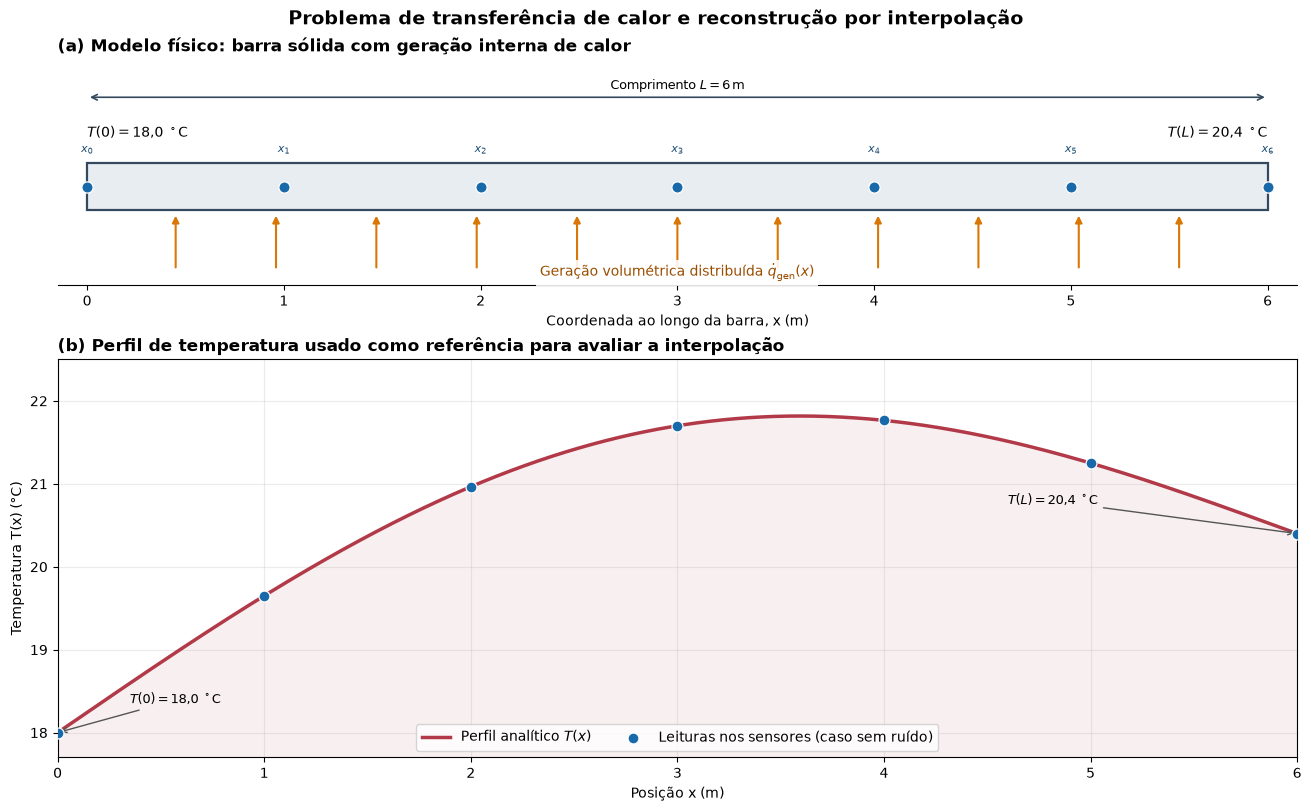

Temperaturas nas extremidades: T(0)=18.0 °C e T(L)=20.4 °C


In [1]:
# Preparação do modelo e bibliotecas
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.interpolate import BarycentricInterpolator, interp1d, CubicSpline
from matplotlib.patches import Rectangle

np.set_printoptions(precision=4, suppress=True)
plt.rcParams["figure.figsize"] = (9, 5)
L = 6.0  # comprimento da barra, m

def temperatura_real(x):
    """Perfil analítico de referência em °C; x é dado em metros."""
    x = np.asarray(x, dtype=float)
    xi = x/L
    return 18 + 2.4*xi + 2.5*np.sin(np.pi*xi)

x_min, x_max = 0.0, L
x_fino = np.linspace(x_min, x_max, 2001)
T_fino = temperatura_real(x_fino)

# Figura do problema: esquema físico e perfil analítico em painéis separados

x_sensores_fig = np.linspace(0, L, 7)
T_sensores_fig = temperatura_real(x_sensores_fig)

fig = plt.figure(figsize=(13, 8), constrained_layout=True)
gs = fig.add_gridspec(2, 1, height_ratios=[0.85, 1.5])
ax_esq = fig.add_subplot(gs[0])
ax_perfil = fig.add_subplot(gs[1])

# Painel (a): barra física, sensores e fonte interna distribuída
ax_esq.set_title("(a) Modelo físico: barra sólida com geração interna de calor", loc="left", fontsize=12, weight="bold")
barra_y, barra_h = 0.40, 0.25
ax_esq.add_patch(Rectangle((0, barra_y), L, barra_h, facecolor="#e8edf2",
                           edgecolor="#34495e", linewidth=1.6, zorder=1))
# Sensores ao longo do eixo da barra
ax_esq.scatter(x_sensores_fig, np.full_like(x_sensores_fig, barra_y+barra_h/2),
               s=65, marker="o", facecolor="#1769aa", edgecolor="white", linewidth=0.9,
               zorder=4, label="Sensores")
# Aquecimento interno: setas iguais identificam geração distribuída, sem sugerir fluxo de calor externo
for xpos in np.linspace(0.45, 5.55, 11):
    ax_esq.annotate("", xy=(xpos, barra_y-0.015), xytext=(xpos, 0.08),
                    arrowprops={"arrowstyle":"-|>", "color":"#d97706", "lw":1.5}, zorder=3)
ax_esq.text(L/2, 0.015, r"Geração volumétrica distribuída $\dot{q}_{\mathrm{gen}}(x)$",
            ha="center", va="bottom", color="#9a4d00", fontsize=10,
            bbox={"facecolor":"white", "edgecolor":"none", "alpha":0.88, "pad":2.5})
ax_esq.text(0, 0.77, r"$T(0)=18{,}0\ ^\circ\mathrm{C}$", ha="left", va="bottom", fontsize=10)
ax_esq.text(L, 0.77, r"$T(L)=20{,}4\ ^\circ\mathrm{C}$", ha="right", va="bottom", fontsize=10)
# Linha de dimensão e eixo longitudinal
ax_esq.annotate("", xy=(L, 1.00), xytext=(0, 1.00),
                arrowprops={"arrowstyle":"<->", "color":"#34495e", "lw":1.2})
ax_esq.text(L/2, 1.025, r"Comprimento $L=6\,\mathrm{m}$", ha="center", va="bottom", fontsize=9)
for i, xpos in enumerate(x_sensores_fig):
    ax_esq.text(xpos, barra_y+barra_h+0.04, rf"$x_{i}$", ha="center", va="bottom", fontsize=8, color="#174a73")
ax_esq.set_xlim(-0.15, L+0.15); ax_esq.set_ylim(0, 1.2)
ax_esq.set_xlabel("Coordenada ao longo da barra, x (m)")
ax_esq.set_yticks([]); ax_esq.grid(False)
for spine in ["left", "right", "top"]: ax_esq.spines[spine].set_visible(False)

# Painel (b): curva de referência e posições amostradas
ax_perfil.set_title("(b) Perfil de temperatura usado como referência para avaliar a interpolação",
                    loc="left", fontsize=12, weight="bold")
ax_perfil.plot(x_fino, T_fino, color="#b23a48", linewidth=2.5,
               label=r"Perfil analítico $T(x)$", zorder=2)
ax_perfil.scatter(x_sensores_fig, T_sensores_fig, s=62, marker="o",
                  facecolor="#1769aa", edgecolor="white", linewidth=0.9,
                  label="Leituras nos sensores (caso sem ruído)", zorder=4)
ax_perfil.fill_between(x_fino, T_fino, np.min(T_fino)-0.3,
                       color="#b23a48", alpha=0.08, zorder=1)
ax_perfil.annotate(r"$T(0)=18{,}0\ ^\circ\mathrm{C}$",
                   xy=(0, temperatura_real(0)), xytext=(0.35, 18.35),
                   arrowprops={"arrowstyle":"->", "color":"#555"}, fontsize=9)
ax_perfil.annotate(r"$T(L)=20{,}4\ ^\circ\mathrm{C}$",
                   xy=(L, temperatura_real(L)), xytext=(4.6, 20.75),
                   arrowprops={"arrowstyle":"->", "color":"#555"}, fontsize=9)
ax_perfil.set_xlim(0, L); ax_perfil.set_ylim(17.7, 22.5)
ax_perfil.set_xlabel("Posição x (m)")
ax_perfil.set_ylabel("Temperatura T(x) (°C)")
ax_perfil.grid(True, alpha=0.25); ax_perfil.legend(loc="lower center", ncol=2, frameon=True)
fig.suptitle("Problema de transferência de calor e reconstrução por interpolação", fontsize=14, weight="bold")
plt.show()

print(f"Temperaturas nas extremidades: T(0)={temperatura_real(0):.1f} °C e T(L)={temperatura_real(L):.1f} °C")

### Complemento do grupo: o perfil satisfaz mesmo a equação?

Antes de usar $T(x)$ como referência, conferimos numericamente o que a seção 1.2 afirma: as temperaturas nas extremidades e a expressão de $d^2T/dx^2$. A segunda derivada é aproximada pela diferença central

$$T''(x)\approx\frac{T(x+h)-2T(x)+T(x-h)}{h^2},$$

cujo erro de truncamento é da ordem de $h^2$.

In [2]:
# Complemento: conferência do perfil de referência
def d2T_exata(x):
    """Segunda derivada analítica do perfil, em °C/m²."""
    return -2.5*np.pi**2/L**2*np.sin(np.pi*np.asarray(x, dtype=float)/L)

h = 1e-3
x_teste = np.array([0.5, 1.5, 3.0, 4.5, 5.5])
d2T_num = (temperatura_real(x_teste+h) - 2*temperatura_real(x_teste) + temperatura_real(x_teste-h))/h**2
for xt, dn, de in zip(x_teste, d2T_num, d2T_exata(x_teste)):
    print(f"x = {xt:3.1f} m | T'' numérica = {dn: .7f} | T'' da fórmula = {de: .7f} | diferença = {abs(dn-de):.1e}")

print(f"\nT''(0) = {d2T_exata(0.0) + 0.0:.1e} °C/m²   e   T''(L) = {d2T_exata(L):.1e} °C/m²")

x = 0.5 m | T'' numérica = -0.1773918 | T'' da fórmula = -0.1773918 | diferença = 9.1e-10
x = 1.5 m | T'' numérica = -0.4846433 | T'' da fórmula = -0.4846433 | diferença = 6.6e-09
x = 3.0 m | T'' numérica = -0.6853892 | T'' da fórmula = -0.6853892 | diferença = 2.0e-08
x = 4.5 m | T'' numérica = -0.4846433 | T'' da fórmula = -0.4846433 | diferença = 1.0e-08
x = 5.5 m | T'' numérica = -0.1773918 | T'' da fórmula = -0.1773918 | diferença = 4.5e-09

T''(0) = 0.0e+00 °C/m²   e   T''(L) = -8.4e-17 °C/m²


**O que a conferência mostra:** a diferença central concorda com a fórmula até a ordem de $10^{-8}$, o tamanho esperado do erro de arredondamento quando se divide por $h^2=10^{-6}$. O detalhe que vamos usar depois é a última linha: $T''(0)=T''(L)=0$ (o valor de $\approx10^{-17}$ em $x=L$ é só $\sin(\pi)$ calculado em ponto flutuante). Fisicamente, isso vem de $kT''=-\dot q'''$ e de a fonte ser nula nas bordas.

É exatamente a condição que a **spline cúbica natural** impõe nas extremidades ($S''=0$). Neste problema, então, a condição "natural" não é uma aproximação arbitrária: ela coincide com a física.

Spline quadrática

In [3]:
def spline_quadratica_coef(x, y):
    """Spline quadrática C1 com condição c_0=0; retorna a,b,c locais."""
    x = np.asarray(x, float); y = np.asarray(y, float)
    n = len(x)-1
    if n < 1 or len(y) != len(x) or np.any(np.diff(x) <= 0):
        raise ValueError("x deve ser crescente e ter o mesmo tamanho de y.")
    A = np.zeros((3*n, 3*n)); rhs = np.zeros(3*n); row = 0
    # S_i(x_i)=y_i
    for i in range(n):
        A[row, i] = 1; rhs[row] = y[i]; row += 1
    # S_i(x_(i+1))=y_(i+1)
    for i in range(n):
        h = x[i+1]-x[i]
        A[row, i] = 1; A[row, n+i] = h; A[row, 2*n+i] = h*h
        rhs[row] = y[i+1]; row += 1
    # Continuidade da primeira derivada nos nós internos
    for i in range(n-1):
        h = x[i+1]-x[i]
        A[row, n+i] = 1; A[row, 2*n+i] = 2*h; A[row, n+i+1] = -1
        row += 1
    # Condição de contorno: c_0=0
    A[row, 2*n] = 1
    coef = np.linalg.solve(A, rhs)
    return coef[:n], coef[n:2*n], coef[2*n:]

def spline_quadratica_avalia(x, coef, xq):
    a, b, c = coef
    xq = np.asarray(xq, dtype=float)
    idx = np.clip(np.searchsorted(x, xq, side="right")-1, 0, len(a)-1)
    t = xq-x[idx]
    return a[idx] + b[idx]*t + c[idx]*t**2

def criar_metodos(x, y):
    """Retorna dicionário: interpoladores callable para quatro métodos."""
    lagrange = BarycentricInterpolator(x, y)
    linear = interp1d(x, y, kind="linear", bounds_error=True)
    quad_coef = spline_quadratica_coef(x, y)
    quad = lambda z: spline_quadratica_avalia(x, quad_coef, z)
    cubica = CubicSpline(x, y, bc_type="natural")
    return {"Lagrange global": lagrange,
            "Spline linear": linear,
            "Spline quadrática": quad,
            "Spline cúbica natural": cubica}

def calcular_metricas(metodos, x_teste, y_verdadeiro):
    linhas = []
    for nome, metodo in metodos.items():
        erro = np.asarray(metodo(x_teste))-np.asarray(y_verdadeiro)
        linhas.append({"Método": nome,
                       "Erro máximo (°C)": np.max(np.abs(erro)),
                       "MAE (°C)": np.mean(np.abs(erro)),
                       "RMSE (°C)": np.sqrt(np.mean(erro**2))})
    return pd.DataFrame(linhas).sort_values("RMSE (°C)").reset_index(drop=True)

print("Funções de interpolação e métricas definidas.")

Funções de interpolação e métricas definidas.


## 3. Métodos de interpolação e métricas de erro

O interpolador global de Lagrange passa por todos os sensores usando um único polinômio. Usamos a forma baricêntrica, que evita expandir diretamente os coeficientes e costuma ser numericamente mais estável.

As splines constroem polinômios por intervalos. A spline linear conecta pontos por retas. A quadrática deste notebook impõe continuidade da função e da primeira derivada e usa a condição de contorno $c_0=0$ no primeiro intervalo. A spline cúbica natural impõe continuidade até a segunda derivada e segunda derivada nula nas extremidades.

Para quantificar a diferença, calculamos $e(x)=T_{interp}(x)-T_{ref}(x)$. O erro máximo mostra o pior desvio na malha. O MAE dá o desvio absoluto médio. O RMSE penaliza mais os erros de grande magnitude. Todos têm unidade de graus Celsius.

A malha fina serve como conjunto de pontos de avaliação: os valores nela não são novos sensores. Assim, a comparação mede desempenho entre os nós.

In [4]:
def spline_quadratica_coef(x, y):
    """Spline quadrática C1 com condição c_0=0; retorna a,b,c locais."""
    x = np.asarray(x, float); y = np.asarray(y, float)
    n = len(x)-1
    if n < 1 or len(y) != len(x) or np.any(np.diff(x) <= 0):
        raise ValueError("x deve ser crescente e ter o mesmo tamanho de y.")
    A = np.zeros((3*n, 3*n)); rhs = np.zeros(3*n); row = 0
    # S_i(x_i)=y_i
    for i in range(n):
        A[row, i] = 1; rhs[row] = y[i]; row += 1
    # S_i(x_(i+1))=y_(i+1)
    for i in range(n):
        h = x[i+1]-x[i]
        A[row, i] = 1; A[row, n+i] = h; A[row, 2*n+i] = h*h
        rhs[row] = y[i+1]; row += 1
    # Continuidade da primeira derivada nos nós internos
    for i in range(n-1):
        h = x[i+1]-x[i]
        A[row, n+i] = 1; A[row, 2*n+i] = 2*h; A[row, n+i+1] = -1
        row += 1
    # Condição de contorno: c_0=0
    A[row, 2*n] = 1
    coef = np.linalg.solve(A, rhs)
    return coef[:n], coef[n:2*n], coef[2*n:]

def spline_quadratica_avalia(x, coef, xq):
    a, b, c = coef
    xq = np.asarray(xq, dtype=float)
    idx = np.clip(np.searchsorted(x, xq, side="right")-1, 0, len(a)-1)
    t = xq-x[idx]
    return a[idx] + b[idx]*t + c[idx]*t**2

def criar_metodos(x, y):
    """Retorna dicionário: interpoladores callable para quatro métodos."""
    lagrange = BarycentricInterpolator(x, y)
    linear = interp1d(x, y, kind="linear", bounds_error=True)
    quad_coef = spline_quadratica_coef(x, y)
    quad = lambda z: spline_quadratica_avalia(x, quad_coef, z)
    cubica = CubicSpline(x, y, bc_type="natural")
    return {"Lagrange global": lagrange,
            "Spline linear": linear,
            "Spline quadrática": quad,
            "Spline cúbica natural": cubica}

def calcular_metricas(metodos, x_teste, y_verdadeiro):
    linhas = []
    for nome, metodo in metodos.items():
        erro = np.asarray(metodo(x_teste))-np.asarray(y_verdadeiro)
        linhas.append({"Método": nome,
                       "Erro máximo (°C)": np.max(np.abs(erro)),
                       "MAE (°C)": np.mean(np.abs(erro)),
                       "RMSE (°C)": np.sqrt(np.mean(erro**2))})
    return pd.DataFrame(linhas).sort_values("RMSE (°C)").reset_index(drop=True)

print("Funções de interpolação e métricas definidas.")

Funções de interpolação e métricas definidas.


## Etapa 1 — Interpolação com dados exatos
Suponha primeiro que os sensores sejam perfeitos. Coloque sete sensores em posições igualmente espaçadas, incluindo as duas extremidades. Os valores registrados são então exatamente $T(x_i)$.

### Passo a passo
1. Construa o vetor das posições e avalie o perfil de referência nesses pontos.
2. Crie a interpolação com `criar_metodos`.
3. Avalie cada método em `x_fino`, uma malha densa entre 0 e 6 m.
4. Calcule $E_{max}$, MAE e RMSE comparando cada curva com `T_fino`.
5. Faça um gráfico das temperaturas e outro dos erros assinados.




,Método,Erro máximo (°C),MAE (°C),RMSE (°C)
0,Lagrange global,8.468e-05,1.918e-05,3.271e-05
1,Spline cúbica natural,5.060e-04,1.841e-04,2.391e-04
2,Spline quadrática,2.393e-02,1.495e-02,1.647e-02
3,Spline linear,8.229e-02,3.651e-02,4.397e-02


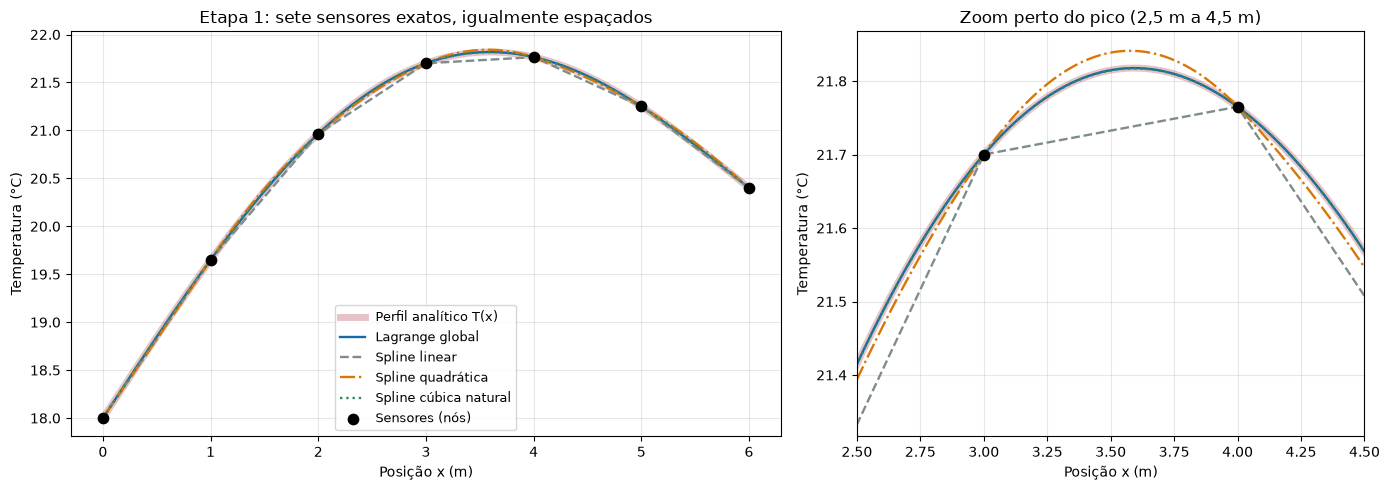

In [5]:
x_nos_7 = np.linspace(x_min, x_max, 7)
y_nos_7 = temperatura_real(x_nos_7)
metodos_7 = criar_metodos(x_nos_7, y_nos_7)

# Tabela de métricas na malha fina (notação científica: os erros vão de 1e-5 a 1e-1 °C)
pd.set_option("display.float_format", "{:.3e}".format)
metricas_7 = calcular_metricas(metodos_7, x_fino, T_fino)
display(metricas_7)

# Os quatro métodos sobrepostos à função verdadeira, com os nós marcados
cores = {"Lagrange global": "#1769aa", "Spline linear": "#7f8c8d",
         "Spline quadrática": "#d97706", "Spline cúbica natural": "#2e8b57"}
estilos = {"Lagrange global": "-", "Spline linear": "--",
           "Spline quadrática": "-.", "Spline cúbica natural": ":"}

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5), gridspec_kw={"width_ratios": [1.4, 1]})
for ax in (ax1, ax2):
    ax.plot(x_fino, T_fino, color="#b23a48", lw=5, alpha=0.3, label="Perfil analítico T(x)")
    for nome, metodo in metodos_7.items():
        ax.plot(x_fino, metodo(x_fino), estilos[nome], color=cores[nome], lw=1.7, label=nome)
    ax.scatter(x_nos_7, y_nos_7, s=55, color="black", zorder=5, label="Sensores (nós)")
    ax.set_xlabel("Posição x (m)"); ax.set_ylabel("Temperatura (°C)"); ax.grid(True, alpha=0.3)
ax1.set_title("Etapa 1: sete sensores exatos, igualmente espaçados")
ax1.legend(loc="lower center", fontsize=9)
zoom = (x_fino >= 2.5) & (x_fino <= 4.5)
ax2.set_xlim(2.5, 4.5); ax2.set_ylim(T_fino[zoom].min() - 0.1, T_fino[zoom].max() + 0.05)
ax2.set_title("Zoom perto do pico (2,5 m a 4,5 m)")
plt.tight_layout(); plt.show()

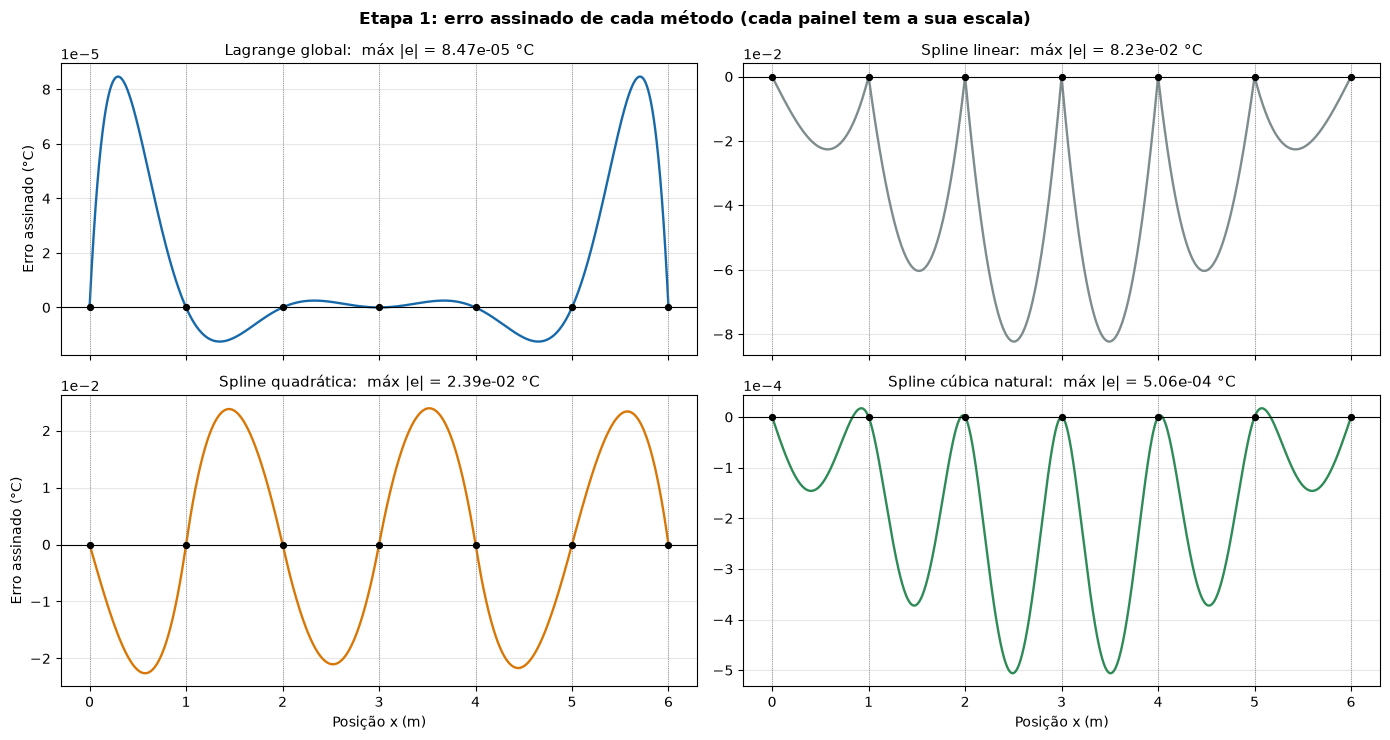

In [6]:
# Erros assinados método a método: e(x) = método(x) − T(x)
fig, eixos = plt.subplots(2, 2, figsize=(14, 7.5), sharex=True)
for ax, (nome, metodo) in zip(eixos.ravel(), metodos_7.items()):
    erro = metodo(x_fino) - T_fino
    ax.plot(x_fino, erro, color=cores[nome], lw=1.7)
    ax.axhline(0, color="black", lw=0.8)
    for xn in x_nos_7:
        ax.axvline(xn, color="gray", lw=0.6, ls=":")
    ax.scatter(x_nos_7, metodo(x_nos_7) - y_nos_7, s=18, color="black", zorder=3)
    ax.set_title(f"{nome}:  máx |e| = {np.max(np.abs(erro)):.2e} °C", fontsize=11)
    ax.ticklabel_format(axis="y", style="sci", scilimits=(-2, 2))
    ax.grid(True, alpha=0.3)
for ax in eixos[1]:
    ax.set_xlabel("Posição x (m)")
for ax in eixos[:, 0]:
    ax.set_ylabel("Erro assinado (°C)")
fig.suptitle("Etapa 1: erro assinado de cada método (cada painel tem a sua escala)", weight="bold")
plt.tight_layout(); plt.show()

**Resposta do grupo (Etapa 1).** Erros na malha fina de 2001 pontos, com sete sensores exatos ($h=1$ m):

| Método | $E_{max}$ (°C) | MAE (°C) | RMSE (°C) |
|---|---|---|---|
| Lagrange global (grau 6) | $8{,}5\times10^{-5}$ | $1{,}9\times10^{-5}$ | $3{,}3\times10^{-5}$ |
| Spline cúbica natural | $5{,}1\times10^{-4}$ | $1{,}8\times10^{-4}$ | $2{,}4\times10^{-4}$ |
| Spline quadrática ($c_0=0$) | $2{,}4\times10^{-2}$ | $1{,}5\times10^{-2}$ | $1{,}6\times10^{-2}$ |
| Spline linear | $8{,}2\times10^{-2}$ | $3{,}7\times10^{-2}$ | $4{,}4\times10^{-2}$ |

- **Classificação:** as três métricas concordam. O polinômio de Lagrange erra cerca de 6 vezes menos que a spline cúbica no erro máximo e cerca de mil vezes menos que a spline linear. No gráfico das temperaturas, Lagrange e spline cúbica nem se separam da curva verdadeira; só a linear e a quadrática aparecem no zoom.
- **Nos nós o erro é zero** em todos os métodos (pontos pretos sobre a linha de zero). O erro mora **entre** os nós, e é por isso que avaliamos na malha fina.
- **Onde fica o erro depende do método.** No Lagrange, o erro é maior nos intervalos das pontas ($8{,}5\times10^{-5}$ °C entre 0 e 1 m e entre 5 e 6 m) e 34 vezes menor no centro ($2{,}5\times10^{-6}$ °C), o comportamento típico do polinômio global. Na spline cúbica é o contrário: o erro é maior no meio da barra ($5{,}1\times10^{-4}$ °C perto de $x=2{,}5$ e $3{,}5$ m) e menor nas pontas ($1{,}5\times10^{-4}$ °C), porque a condição natural $S''=0$ está correta neste perfil (complemento da seção 2).
- **Spline linear:** o erro é sempre negativo. O perfil é côncavo ($T''<0$), e a reta entre dois sensores sempre passa abaixo de uma curva côncava. O máximo, $0{,}082$ °C, aparece nos intervalos centrais, onde a curvatura é maior.
- **Spline quadrática:** erro de cerca de $0{,}02$ °C em **todos** os intervalos e sem simetria, embora os dados sejam simétricos em torno de $x=3$ m. A condição $c_0=0$ é imposta só na ponta esquerda, e o erro de curvatura vai passando de um trecho para o seguinte, alternando para mais e para menos (complemento abaixo).
- **Na prática:** com dados exatos, até a pior opção erra menos de 0,1 °C, e Lagrange e spline cúbica ficam centenas a milhares de vezes abaixo da resolução de um termômetro comum ($\approx0{,}1$ °C). Com sete sensores exatos, o erro de truncamento não é o que limita a estimativa.

### Complemento do grupo: os erros batem com as fórmulas teóricas?

Para dados exatos, as fórmulas clássicas dão cotas para o erro:

- spline linear: $|e(x)|\le \dfrac{h^2}{8}\max|T''|$;
- polinômio de Lagrange com $n+1$ nós: $e(x)=\dfrac{T^{(n+1)}(\xi)}{(n+1)!}\,\omega(x)$, com $\omega(x)=\prod_i(x-x_i)$, logo $|e(x)|\le \dfrac{\max|T^{(n+1)}|}{(n+1)!}\max|\omega|$;
- spline cúbica: $|e(x)|\le \dfrac{5}{384}h^4\max|T^{(4)}|$ (cota clássica da spline com derivadas fixadas nas pontas).

As derivadas do perfil são fáceis: a parcela linear some a partir da segunda derivada e $\left|\dfrac{d^n}{dx^n}\,2{,}5\sin\dfrac{\pi x}{L}\right|\le 2{,}5\left(\dfrac{\pi}{L}\right)^n$.

In [7]:
# Complemento: cotas teóricas × erros medidos (7 nós, h = 1 m)
import math

h7 = x_nos_7[1] - x_nos_7[0]
max_deriv = lambda n: 2.5*(np.pi/L)**n          # máximo de |T^(n)| para n >= 2

omega = np.prod([x_fino - xi for xi in x_nos_7], axis=0)
erros_7 = {nome: np.max(np.abs(m(x_fino) - T_fino)) for nome, m in metodos_7.items()}
cotas = {"Spline linear": h7**2/8*max_deriv(2),
         "Lagrange global": max_deriv(7)/math.factorial(7)*np.max(np.abs(omega)),
         "Spline cúbica natural": 5/384*h7**4*max_deriv(4)}
for nome, cota in cotas.items():
    print(f"{nome:22s} | cota = {cota:.2e} °C | erro medido = {erros_7[nome]:.2e} °C | medido/cota = {erros_7[nome]/cota:.2f}")

print(f"\nmax|ω(x)| = {np.max(np.abs(omega)):.1f}, em x = {x_fino[np.argmax(np.abs(omega))]:.2f} m (perto da ponta)")
print(f"|ω(3,5)|  = {abs(np.prod(3.5 - x_nos_7)):.1f} (no centro)")

a_q, b_q, c_q = spline_quadratica_coef(x_nos_7, y_nos_7)
meio = x_nos_7[:-1] + h7/2
print("\nCurvatura da spline quadrática em cada trecho (2c_i):", np.round(2*c_q, 3))
print("Curvatura verdadeira T'' no meio de cada trecho:      ", np.round(d2T_exata(meio), 3))

Spline linear          | cota = 8.57e-02 °C | erro medido = 8.23e-02 °C | medido/cota = 0.96
Lagrange global        | cota = 5.13e-04 °C | erro medido = 8.47e-05 °C | medido/cota = 0.17
Spline cúbica natural  | cota = 2.45e-03 °C | erro medido = 5.06e-04 °C | medido/cota = 0.21

max|ω(x)| = 95.8, em x = 0.32 m (perto da ponta)
|ω(3,5)|  = 12.3 (no centro)

Curvatura da spline quadrática em cada trecho (2c_i): [ 0.    -0.67  -0.49  -0.849 -0.311 -0.359]
Curvatura verdadeira T'' no meio de cada trecho:       [-0.177 -0.485 -0.662 -0.662 -0.485 -0.177]


**Leitura:** as três cotas são respeitadas. A da spline linear é quase atingida (o erro medido é 96% da cota), porque nos intervalos centrais $T''$ é praticamente constante. As outras duas sobram com folga de 5 a 6 vezes, porque usam o pior valor possível da derivada. O fator $\omega(x)$ explica por que o erro do Lagrange mora nas pontas: $|\omega|$ chega a $\approx96$ perto de $x=0{,}3$ m e vale só $\approx12$ em $x=3{,}5$ m.

Na spline quadrática, a curvatura de cada trecho deveria acompanhar $T''$, que é simétrica (de $-0{,}18$ °C/m² nos trechos das pontas a $-0{,}66$ °C/m² no centro). Mas ela começa obrigatoriamente em $0$ ($c_0=0$) e depois alterna para mais e para menos ($-0{,}67$; $-0{,}49$; $-0{,}85$; $-0{,}31$; $-0{,}36$): cada trecho tenta compensar o anterior. É a fraqueza da spline quadrática: uma condição de contorno numa só ponta se propaga pela barra inteira.

## Etapa 2 — Número e posição dos sensores

Nesta etapa, investigue somente o polinômio global de Lagrange. A interpolação polinomial global pode oscilar entre nós, sobretudo perto das extremidades, quando se usam muitos nós equiespaçados. A distribuição de Chebyshev concentra nós nas bordas e pode reduzir esse efeito.

Para $N$ nós de Chebyshev-Lobatto em $[a,b]$, use

$$x_k=\frac{a+b}{2}+\frac{b-a}{2}\cos\left(\frac{k\pi}{N-1}\right),\quad k=0,\ldots,N-1.$$

Ordene as posições crescentemente. Compare $N=5,9,13,17$ para nós equiespaçados e de Chebyshev. Para cada caso, avalie o erro em todos os pontos da malha fina e registre o erro máximo e o RMSE.

**Atenção:** uma redução de erro neste perfil particular não prova que o mesmo ocorrerá para qualquer função. Relacione a observação à suavidade e à estrutura do perfil usado.

In [8]:
def nos_chebyshev_lobatto(a, b, N):
    k = np.arange(N)
    z = np.cos(k*np.pi/(N-1))
    return np.sort((a+b)/2 + (b-a)*z/2)

def metricas_erro(interpolador, x_teste=x_fino, y_ref=T_fino):
    """Devolve (erro máximo, RMSE) de um interpolador na malha de teste."""
    erro = interpolador(x_teste) - y_ref
    return np.max(np.abs(erro)), np.sqrt(np.mean(erro**2))

linhas = []
for N in [5, 9, 13, 17]:
    for distribuicao, nos in [("Equiespaçados", np.linspace(x_min, x_max, N)),
                              ("Chebyshev-Lobatto", nos_chebyshev_lobatto(x_min, x_max, N))]:
        p = BarycentricInterpolator(nos, temperatura_real(nos))
        emax, rmse = metricas_erro(p)
        x_pior = x_fino[np.argmax(np.abs(p(x_fino) - T_fino))]
        linhas.append({"N": N, "Nós": distribuicao, "Erro máximo (°C)": emax,
                       "RMSE (°C)": rmse, "Posição do pior erro (m)": x_pior})
tabela_nos = pd.DataFrame(linhas)
display(tabela_nos.style.format({"Erro máximo (°C)": "{:.3e}", "RMSE (°C)": "{:.3e}",
                                 "Posição do pior erro (m)": "{:.2f}"}).hide(axis="index"))

print("Quantas vezes os nós de Chebyshev reduziram o erro:")
print(" N | Emax equi / Emax Cheb | RMSE equi / RMSE Cheb")
for N in [5, 9, 13, 17]:
    eq = tabela_nos[(tabela_nos["N"] == N) & (tabela_nos["Nós"] == "Equiespaçados")].iloc[0]
    ch = tabela_nos[(tabela_nos["N"] == N) & (tabela_nos["Nós"] == "Chebyshev-Lobatto")].iloc[0]
    print(f"{N:2d} | {eq['Erro máximo (°C)']/ch['Erro máximo (°C)']:21.1f} | {eq['RMSE (°C)']/ch['RMSE (°C)']:21.1f}")

N,Nós,Erro máximo (°C),RMSE (°C),Posição do pior erro (m)
5,Equiespaçados,4.530e-03,2.160e-03,0.47
5,Chebyshev-Lobatto,2.327e-03,1.533e-03,4.37
9,Equiespaçados,1.044e-06,3.438e-07,0.21
9,Chebyshev-Lobatto,2.168e-07,1.202e-07,4.70
13,Equiespaçados,5.919e-11,1.546e-11,0.14
13,Chebyshev-Lobatto,3.624e-12,1.932e-12,1.16
17,Equiespaçados,1.990e-12,2.445e-13,5.90
17,Chebyshev-Lobatto,1.421e-14,3.771e-15,4.48


Quantas vezes os nós de Chebyshev reduziram o erro:
 N | Emax equi / Emax Cheb | RMSE equi / RMSE Cheb
 5 |                   1.9 |                   1.4
 9 |                   4.8 |                   2.9
13 |                  16.3 |                   8.0
17 |                 140.0 |                  64.9


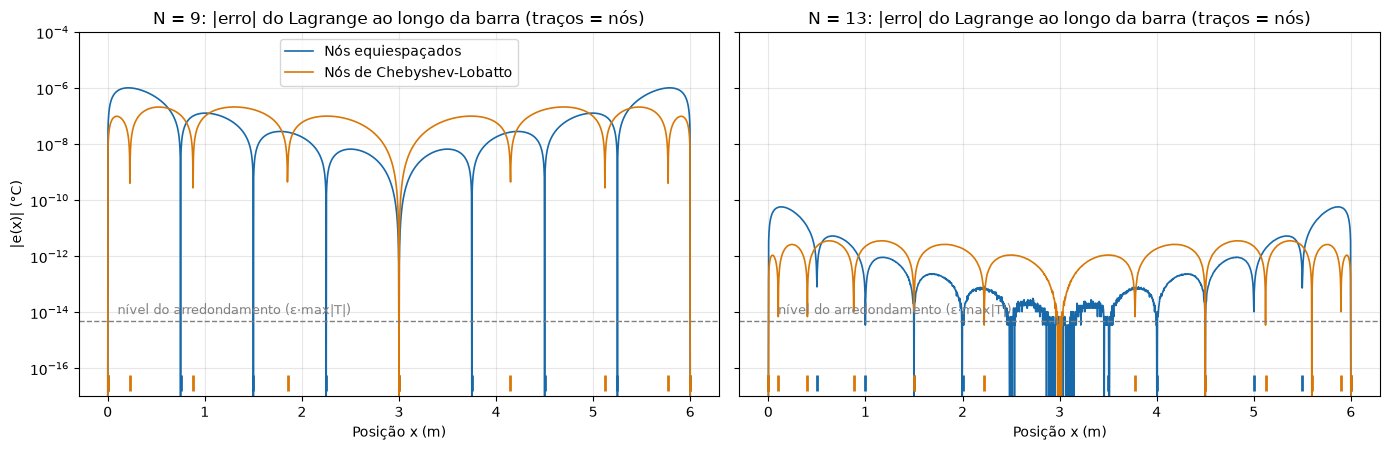

In [9]:
# Onde fica o erro: |e(x)| em escala logarítmica para N = 9 e N = 13
eps_T = np.finfo(float).eps*np.max(np.abs(T_fino))     # tamanho de um "último algarismo" de T
fig, eixos = plt.subplots(1, 2, figsize=(14, 4.6), sharey=True)
for ax, N in zip(eixos, [9, 13]):
    for distribuicao, nos, cor in [("Equiespaçados", np.linspace(x_min, x_max, N), "#1769aa"),
                                   ("Chebyshev-Lobatto", nos_chebyshev_lobatto(x_min, x_max, N), "#d97706")]:
        p = BarycentricInterpolator(nos, temperatura_real(nos))
        ax.semilogy(x_fino, np.abs(p(x_fino) - T_fino) + 1e-18, color=cor, lw=1.2, label="Nós " + ("equiespaçados" if distribuicao == "Equiespaçados" else "de Chebyshev-Lobatto"))
        ax.plot(nos, np.full(N, 3e-17), "|", color=cor, ms=11, mew=2)
    ax.axhline(eps_T, color="gray", ls="--", lw=1)
    ax.text(0.1, eps_T*1.8, "nível do arredondamento (ε·max|T|)", ha="left", fontsize=9, color="gray")
    ax.set_ylim(1e-17, 1e-4); ax.set_xlabel("Posição x (m)")
    ax.set_title(f"N = {N}: |erro| do Lagrange ao longo da barra (traços = nós)")
    ax.grid(True, which="major", alpha=0.3)
eixos[0].set_ylabel("|e(x)| (°C)"); eixos[0].legend(loc="upper center")
plt.tight_layout(); plt.show()

**Resposta do grupo (Etapa 2).** Erros em °C:

| $N$ | $E_{max}$ equiespaçado | $E_{max}$ Chebyshev | RMSE equiespaçado | RMSE Chebyshev | Ganho de Chebyshev ($E_{max}$) |
|---|---|---|---|---|---|
| 5 | $4{,}5\times10^{-3}$ | $2{,}3\times10^{-3}$ | $2{,}2\times10^{-3}$ | $1{,}5\times10^{-3}$ | 1,9 vez |
| 9 | $1{,}0\times10^{-6}$ | $2{,}2\times10^{-7}$ | $3{,}4\times10^{-7}$ | $1{,}2\times10^{-7}$ | 4,8 vezes |
| 13 | $5{,}9\times10^{-11}$ | $3{,}6\times10^{-12}$ | $1{,}5\times10^{-11}$ | $1{,}9\times10^{-12}$ | 16 vezes |
| 17 | $2{,}0\times10^{-12}$ | $1{,}4\times10^{-14}$ | $2{,}4\times10^{-13}$ | $3{,}9\times10^{-15}$ | 140 vezes |

- **As duas distribuições melhoram muito depressa.** De 5 para 17 nós o erro cai de $10^{-3}$ para $10^{-12}$ a $10^{-14}$ °C. O fenômeno de Runge não apareceu: mais nós equiespaçados melhoraram o resultado em toda a faixa testada.
- **Chebyshev sempre ganha, e o ganho cresce com $N$** (de 1,9 para 140 vezes no erro máximo; no RMSE, de 1,4 para 64 vezes). Com nós equiespaçados, o pior ponto fica sempre perto das pontas ($x\approx0{,}1$ a $0{,}5$ m ou $x\approx5{,}9$ m); com Chebyshev, o erro se espalha de maneira uniforme pela barra (gráfico acima). Concentrar nós nas pontas encolhe o fator $\omega(x)$ justamente onde ele era maior.
- **Em $N=17$, Chebyshev chega ao limite da máquina:** $1{,}4\times10^{-14}$ °C são poucos "últimos algarismos" de um número da ordem de 20 (linha cinza nos gráficos da Etapa 3). O equiespaçado, por sua vez, melhorou só 30 vezes de 13 para 17 nós, contra 18 mil vezes de 9 para 13: o arredondamento já começou a pesar, como a Etapa 3 confirma.

**Por que funcionou aqui, e por que não é regra.** O perfil é uma reta mais um seno: uma função **inteira** (sem singularidades nem no plano complexo), cujas derivadas são limitadas por $2{,}5(\pi/6)^n$, com $\pi/6\approx0{,}52<1$. Na fórmula do erro, $\max|T^{(N)}|/N!$ vai a zero muito depressa, seja qual for a distribuição de nós. A função de Runge da atividade anterior, $1/(1+25x^2)$, tem polos em $\pm0{,}2\,i$, muito perto do intervalo, e derivadas que crescem como $N!\,5^N$; ali os nós equiespaçados divergiram (erro máximo de 0,44 com 5 nós e de 7,2 com 15). Um perfil real com aquecimento localizado, junção de dois materiais ou um "bico" se pareceria mais com Runge do que com este seno. A redução que vimos é uma propriedade deste perfil suave, não do método.

## Etapa 3 — Estudo de caso e decisão técnica

Faça $N$ variar de 4 a 40. Compare erro máximo e RMSE em escala logarítmica para Lagrange equiespaçado, Lagrange com Chebyshev e spline cúbica natural. Registre o tempo de construção e de avaliação. Discuta o custo e a estabilidade numérica. Para o perfil suave escolhido, haverá necessariamente um único método superior para todo $N$?

In [10]:
import time

def cronometrar(funcao, repeticoes=30):
    """Menor tempo (s) entre várias repetições: reduz a interferência de outros processos."""
    melhor = np.inf
    for _ in range(repeticoes):
        t0 = time.perf_counter(); funcao(); melhor = min(melhor, time.perf_counter() - t0)
    return melhor

# nome: (como gerar os nós, como construir o interpolador)
construtores = {
    "Lagrange equiespaçado": (lambda N: np.linspace(x_min, x_max, N), BarycentricInterpolator),
    "Lagrange Chebyshev":    (lambda N: nos_chebyshev_lobatto(x_min, x_max, N), BarycentricInterpolator),
    "Spline cúbica natural": (lambda N: np.linspace(x_min, x_max, N), lambda x, y: CubicSpline(x, y, bc_type="natural")),
}

linhas = []
for N in range(4, 41):
    for nome, (gera_nos, constroi) in construtores.items():
        x_n = gera_nos(N); y_n = temperatura_real(x_n)
        interp = constroi(x_n, y_n)
        emax, rmse = metricas_erro(interp)
        linhas.append({"N": N, "Método": nome, "Erro máximo (°C)": emax, "RMSE (°C)": rmse,
                       "Construção (ms)": 1e3*cronometrar(lambda: constroi(x_n, y_n)),
                       "Avaliação em x_fino (ms)": 1e3*cronometrar(lambda: interp(x_fino))})
estudo = pd.DataFrame(linhas)

amostra = [4, 5, 6, 7, 8, 9, 10, 15, 20, 25, 30, 35, 36, 38, 39, 40]
print("Erro máximo (°C):")
display(estudo[estudo["N"].isin(amostra)].pivot(index="N", columns="Método", values="Erro máximo (°C)"))
print("RMSE (°C):")
display(estudo[estudo["N"].isin(amostra)].pivot(index="N", columns="Método", values="RMSE (°C)"))

def faixas(serie):
    """Agrupa valores consecutivos de N com o mesmo vencedor."""
    grupos = []
    for N, vencedor in serie.items():
        if grupos and grupos[-1][2] == vencedor: grupos[-1][1] = N
        else: grupos.append([N, N, vencedor])
    return [f"N = {a}" + (f" a {b}" if b != a else "") + f": {v}" for a, b, v in grupos]

for metrica in ["Erro máximo (°C)", "RMSE (°C)"]:
    tab = estudo.pivot(index="N", columns="Método", values=metrica)
    print(f"\nMenor {metrica[:-5]} entre os três métodos:")
    print("   " + "\n   ".join(faixas(tab.idxmin(axis=1))))
    print(f"Só Lagrange equiespaçado × spline cúbica ({metrica[:-5]}):")
    print("   " + "\n   ".join(faixas(tab[["Lagrange equiespaçado", "Spline cúbica natural"]].idxmin(axis=1))))

Erro máximo (°C):


Método,Lagrange Chebyshev,Lagrange equiespaçado,Spline cúbica natural
N,,,
4,1.430e-01,1.090e-01,1.018e-02
5,2.327e-03,4.530e-03,2.665e-03
6,3.017e-03,3.282e-03,1.118e-03
7,3.352e-05,8.468e-05,5.060e-04
8,3.376e-05,6.095e-05,2.777e-04
9,2.168e-07,1.044e-06,1.578e-04
10,2.338e-07,7.517e-07,9.963e-05
15,2.132e-14,9.379e-13,1.661e-05
20,1.421e-14,1.132e-11,4.900e-06


RMSE (°C):


Método,Lagrange Chebyshev,Lagrange equiespaçado,Spline cúbica natural
N,,,
4,8.094e-02,6.830e-02,4.787e-03
5,1.533e-03,2.160e-03,1.333e-03
6,1.725e-03,1.512e-03,5.133e-04
7,1.732e-05,3.271e-05,2.391e-04
8,1.937e-05,2.251e-05,1.264e-04
9,1.202e-07,3.438e-07,7.306e-05
10,1.344e-07,2.375e-07,4.518e-05
15,6.462e-15,1.175e-13,7.553e-06
20,4.173e-15,1.096e-12,2.211e-06



Menor Erro máximo entre os três métodos:
   N = 4: Spline cúbica natural
   N = 5: Lagrange Chebyshev
   N = 6: Spline cúbica natural
   N = 7 a 40: Lagrange Chebyshev
Só Lagrange equiespaçado × spline cúbica (Erro máximo):
   N = 4 a 6: Spline cúbica natural
   N = 7 a 35: Lagrange equiespaçado
   N = 36 a 40: Spline cúbica natural

Menor RMSE entre os três métodos:
   N = 4 a 6: Spline cúbica natural
   N = 7 a 40: Lagrange Chebyshev
Só Lagrange equiespaçado × spline cúbica (RMSE):
   N = 4 a 6: Spline cúbica natural
   N = 7 a 38: Lagrange equiespaçado
   N = 39 a 40: Spline cúbica natural


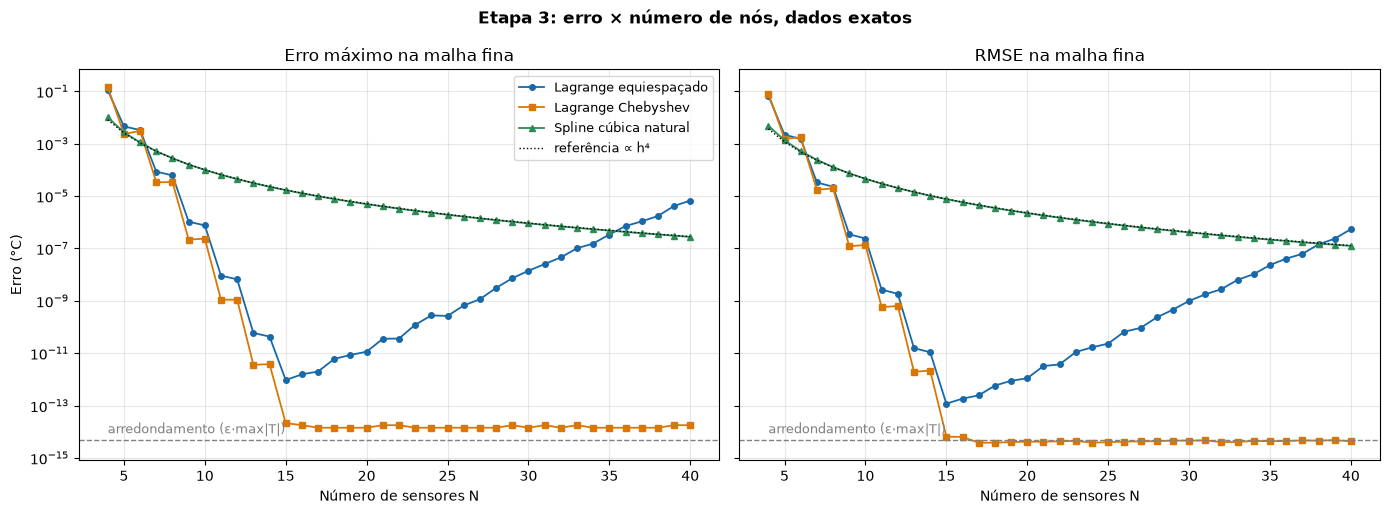

In [11]:
# Erro máximo e RMSE em escala logarítmica
estilo_metodo = {"Lagrange equiespaçado": ("#1769aa", "o"), "Lagrange Chebyshev": ("#d97706", "s"),
                 "Spline cúbica natural": ("#2e8b57", "^")}
fig, eixos = plt.subplots(1, 2, figsize=(14, 5.2), sharey=True)
for ax, metrica in zip(eixos, ["Erro máximo (°C)", "RMSE (°C)"]):
    for nome, (cor, marca) in estilo_metodo.items():
        dados = estudo[estudo["Método"] == nome]
        ax.semilogy(dados["N"], dados[metrica], marker=marca, ms=4, lw=1.3, color=cor, label=nome)
    # referência de inclinação h^4 para a spline, ancorada em N = 10
    spl = estudo[estudo["Método"] == "Spline cúbica natural"].set_index("N")[metrica]
    Ns = np.arange(4, 41)
    ax.semilogy(Ns, spl[10]*((Ns-1)/9.0)**-4, "k:", lw=1, label="referência ∝ h⁴")
    ax.axhline(eps_T, color="gray", ls="--", lw=1)
    ax.text(4, eps_T*1.8, "arredondamento (ε·max|T|)", ha="left", fontsize=9, color="gray")
    ax.set_xlabel("Número de sensores N"); ax.set_title(f"{metrica[:-5]} na malha fina")
    ax.grid(True, which="major", alpha=0.3)
eixos[0].set_ylabel("Erro (°C)"); eixos[0].legend(fontsize=9)
fig.suptitle("Etapa 3: erro × número de nós, dados exatos", weight="bold")
plt.tight_layout(); plt.show()

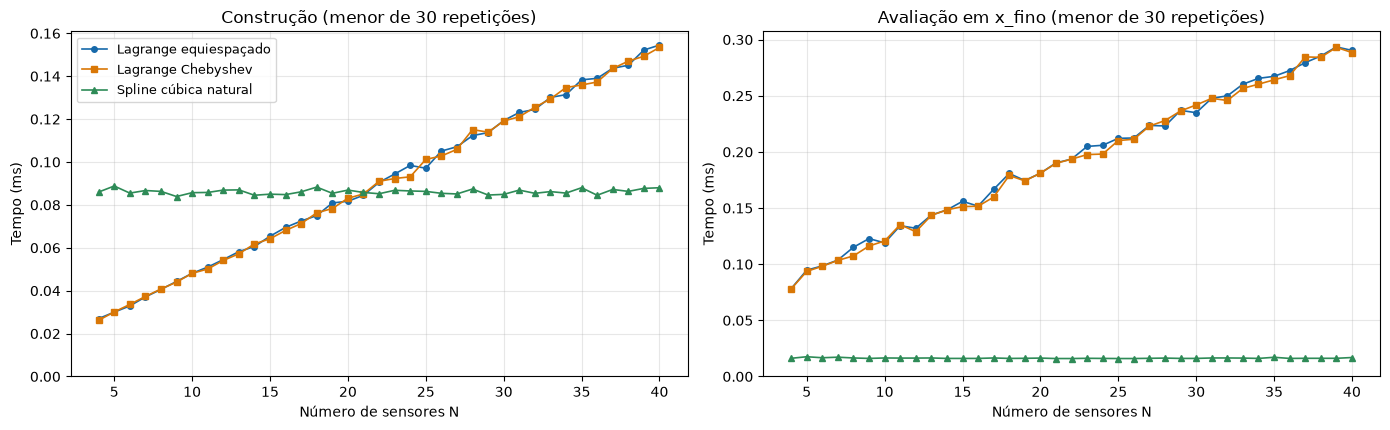

          Construção (ms)                                             Avaliação em x_fino (ms)                                            
Método Lagrange Chebyshev Lagrange equiespaçado Spline cúbica natural       Lagrange Chebyshev Lagrange equiespaçado Spline cúbica natural
N                                                                                                                                         
4                   0.026                 0.027                 0.086                    0.078                 0.078                 0.016
10                  0.048                 0.048                 0.086                    0.121                 0.119                 0.017
20                  0.083                 0.082                 0.087                    0.181                 0.181                 0.016
40                  0.153                 0.155                 0.088                    0.289                 0.290                 0.017


In [12]:
# Custo: tempo de construção e de avaliação nos 2001 pontos da malha fina
fig, eixos = plt.subplots(1, 2, figsize=(14, 4.4))
for ax, coluna in zip(eixos, ["Construção (ms)", "Avaliação em x_fino (ms)"]):
    for nome, (cor, marca) in estilo_metodo.items():
        dados = estudo[estudo["Método"] == nome]
        ax.plot(dados["N"], dados[coluna], marker=marca, ms=4, lw=1.2, color=cor, label=nome)
    ax.set_xlabel("Número de sensores N"); ax.set_ylabel("Tempo (ms)")
    ax.set_title(coluna.replace(" (ms)", "") + " (menor de 30 repetições)")
    ax.set_ylim(bottom=0); ax.grid(True, alpha=0.3)
eixos[0].legend(fontsize=9); plt.tight_layout(); plt.show()

print(estudo[estudo["N"].isin([4, 10, 20, 40])]
      .pivot(index="N", columns="Método", values=["Construção (ms)", "Avaliação em x_fino (ms)"])
      .to_string(float_format="{:.3f}".format))

### Complemento do grupo: por que o Lagrange equiespaçado volta a piorar?

A interpolação é **linear nos dados**: $p(x)=\sum_i y_i\,\ell_i(x)$, em que $\ell_i$ vale 1 no nó $i$ e 0 nos demais. Se cada dado tiver um erro de no máximo $\delta$ (arredondamento ou ruído do sensor), a curva pode errar até

$$|\Delta p(x)|\le \delta\sum_i|\ell_i(x)|\le \delta\,\Lambda_N,\qquad \Lambda_N=\max_x\sum_i|\ell_i(x)|.$$

$\Lambda_N$ é a **constante de Lebesgue**: o fator de amplificação dos erros nos dados. A spline também é linear nos dados, então a mesma conta vale para ela. Calculamos $\Lambda_N$ interpolando os vetores $(0,\dots,0,1,0,\dots,0)$, cujo interpolador é a própria função $\ell_i$.

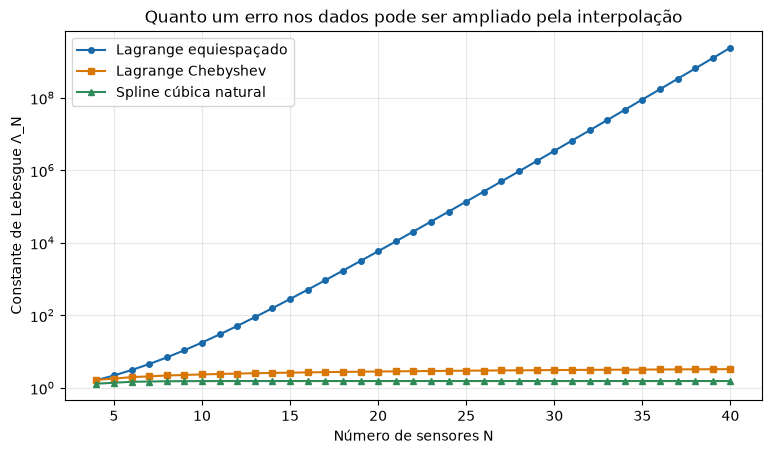

 N | Λ equiespaçado | Λ Chebyshev | Λ spline | ε·max|T|·Λ equi (°C) | Emax medido, equi (°C)
 7 |           4.55 |        2.08 |      1.5 |              2.2e-14 | 8.5e-05
13 |           89.3 |        2.54 |     1.55 |              4.3e-13 | 5.9e-11
17 |            934 |        2.72 |     1.55 |              4.5e-12 | 2.0e-12
25 |       1.38e+05 |        2.98 |     1.55 |              6.7e-10 | 2.6e-10
33 |       2.43e+07 |        3.17 |     1.55 |              1.2e-07 | 1.0e-07
40 |       2.42e+09 |        3.29 |     1.55 |              1.2e-05 | 6.7e-06


In [13]:
def constante_lebesgue(nos, construir, x_teste=x_fino):
    """Λ = max_x Σ|ℓ_i(x)|, com ℓ_i obtida interpolando o vetor com 1 no nó i e 0 nos demais."""
    soma = np.zeros_like(x_teste)
    for i in range(len(nos)):
        base = np.zeros(len(nos)); base[i] = 1.0
        soma += np.abs(construir(nos, base)(x_teste))
    return soma.max()

Ns = np.arange(4, 41)
lebesgue = {nome: [constante_lebesgue(gera(N), constroi) for N in Ns]
            for nome, (gera, constroi) in construtores.items()}

plt.figure(figsize=(9, 4.8))
for nome, (cor, marca) in estilo_metodo.items():
    plt.semilogy(Ns, lebesgue[nome], marker=marca, ms=4, color=cor, label=nome)
plt.xlabel("Número de sensores N"); plt.ylabel("Constante de Lebesgue Λ_N")
plt.title("Quanto um erro nos dados pode ser ampliado pela interpolação")
plt.grid(True, which="major", alpha=0.3); plt.legend(); plt.show()

print(" N | Λ equiespaçado | Λ Chebyshev | Λ spline | ε·max|T|·Λ equi (°C) | Emax medido, equi (°C)")
for N in [7, 13, 17, 25, 33, 40]:
    k = N - 4
    emax_eq = estudo[(estudo["N"] == N) & (estudo["Método"] == "Lagrange equiespaçado")]["Erro máximo (°C)"].iloc[0]
    print(f"{N:2d} | {lebesgue['Lagrange equiespaçado'][k]:14.3g} | {lebesgue['Lagrange Chebyshev'][k]:11.3g} | "
          f"{lebesgue['Spline cúbica natural'][k]:8.3g} | {eps_T*lebesgue['Lagrange equiespaçado'][k]:20.1e} | {emax_eq:.1e}")

**Resposta do grupo (Etapa 3).**

**O que os gráficos mostram.** Os três métodos caem de jeitos diferentes:
- **Lagrange com Chebyshev** cai depressa até a casa de $10^{-14}$ °C em $N=15$ e para aí. É o piso do arredondamento: as temperaturas são da ordem de 20 °C e a precisão dupla guarda cerca de 16 algarismos, então $\varepsilon\cdot\max|T|\approx5\times10^{-15}$ °C. Melhor que isso o computador não consegue.
- **Lagrange equiespaçado** também cai depressa, até um mínimo de $\approx10^{-12}$ °C perto de $N=15$, mas depois **volta a subir**: $\sim10^{-11}$ em $N=20$, $\sim10^{-8}$ em $N=30$ e $\sim10^{-5}$ °C em $N=40$ (os valores exatos dessa subida mudam um pouco de uma máquina para outra, porque são erro de arredondamento). Pela fórmula do erro, o truncamento continuaria caindo; o que cresce é o arredondamento amplificado (complemento acima).
- **Spline cúbica natural** cai de forma algébrica, como $h^4$ (acompanha a linha pontilhada): de $1{,}0\times10^{-2}$ °C ($N=4$) para $2{,}8\times10^{-7}$ °C ($N=40$). Dobrar o número de intervalos ($N=10\to19$) dividiu o erro máximo por $\approx16=2^4$. É mais lenta que o polinômio, mas nunca piora.
- O Lagrange anda **em degraus**: de $N=7$ para $N=8$ quase não melhora ($8{,}5\times10^{-5}\to6{,}1\times10^{-5}$ °C), e de 8 para 9 o erro cai 60 vezes. A parcela linear do perfil é reproduzida exatamente, e a senoidal é simétrica em torno de $x=3$ m. Com nós simétricos, o interpolador também sai simétrico e só usa potências pares de $(x-3)$. Com $N$ par, o termo de maior grau (ímpar) é nulo, e o polinômio rende o mesmo que um de grau menor.

**Existe um único método melhor para todo $N$? Não.**
- $N=4$ e $N=6$: a spline vence nas duas métricas. Em $N=4$, ela erra 10 vezes menos que o polinômio de grau 3 ($1{,}0\times10^{-2}$ contra $1{,}1\times10^{-1}$ °C).
- $N=5$: depende da métrica. Chebyshev tem o menor $E_{max}$ ($2{,}3\times10^{-3}$ contra $2{,}7\times10^{-3}$ °C), mas a spline tem o menor RMSE ($1{,}3\times10^{-3}$ contra $1{,}5\times10^{-3}$ °C).
- $N\ge7$: Chebyshev vence nas duas métricas.
- Comparando só os dois métodos com sensores igualmente espaçados (o caso comum na prática): o polinômio vence de $N=7$ a $N=35$ no $E_{max}$ (até $N=38$ no RMSE), e a spline volta a vencer a partir de $N=36$ (a partir de $N=39$ no RMSE), por causa do arredondamento. Como essa virada depende do arredondamento, ela pode andar uma ou duas unidades em outra máquina.

Ou seja, a resposta depende do número de sensores, de onde eles estão e da métrica escolhida. Mesmo com um perfil tão suave, não há um vencedor único.

**Custo.** Na nossa execução, construir o Lagrange levou de $\approx0{,}03$ ms ($N=4$) a $\approx0{,}15$ ms ($N=40$), crescendo com $N$ porque os pesos baricêntricos custam $O(N^2)$ operações. A spline levou $\approx0{,}09$ ms quase constante: resolver o sistema tridiagonal custa $O(N)$, e o tempo fica dominado pelo custo fixo de chamar a função. Avaliar nos 2001 pontos levou de $\approx0{,}08$ a $\approx0{,}3$ ms no Lagrange ($O(N\,m)$: cada ponto usa todos os nós) e $\approx0{,}02$ ms na spline ($O(m\log N)$: acha o intervalo e avalia um polinômio cúbico). Com $N\le40$ tudo leva menos de um milissegundo, então o custo não decide a escolha aqui. Ele passaria a pesar com milhares de sensores ou com milhões de avaliações, e aí a spline leva vantagem.

**Estabilidade.** A forma baricêntrica evita montar a matriz de Vandermonde, que fica muito mal condicionada com grau alto. Mesmo assim, ela não salva os nós equiespaçados, porque o mal condicionamento é do próprio problema. A constante de Lebesgue mostra isso: com nós equiespaçados ela cresce exponencialmente ($\Lambda\approx4{,}6$ com 7 nós, $\approx930$ com 17 e $\approx2\times10^{9}$ com 40); com Chebyshev ela fica abaixo de 3,3 até $N=40$; na spline cúbica ela para em $\approx1{,}5$, qualquer que seja $N$. Multiplicando o arredondamento dos dados ($\approx5\times10^{-15}$ °C) por $\Lambda=2\times10^9$, chega-se a $\approx10^{-5}$ °C, exatamente o erro observado em $N=40$. A tabela do complemento mostra a troca de regime: até $N=13$ o erro medido é muito maior que $\varepsilon\cdot\max|T|\cdot\Lambda$ (manda o truncamento); a partir de $N=17$ os dois andam juntos (manda o arredondamento). A spline resolve um sistema tridiagonal diagonalmente dominante, estável para qualquer $N$. E, como veremos na Etapa 4, a mesma $\Lambda$ que amplifica o arredondamento amplifica o ruído dos sensores, que é bilhões de vezes maior.

## Etapa 4 — Estudo de caso e decisão técnica

Uma equipe precisa estimar a temperatura em posições internas da barra, com sensores ruidosos. Não haverá sensores em todos os pontos e a solução verdadeira será desconhecida em campo. Com base nos experimentos, escreva uma recomendação técnica.

A recomendação deve responder:
- que método escolheria com poucos sensores exatos e por quê;
- como a recomendação muda quando se aumenta o número de sensores;
- o que faria quando os sensores apresentam ruído;
- que cuidados adotaria perto das extremidades;
- que limitações permanecem quando a temperatura verdadeira não é conhecida.

Use pelo menos duas métricas da atividade. Diferencie interpolação dentro do intervalo medido de extrapolação além dele.

### Complemento do grupo: experimento com sensores ruidosos

A Etapa 4 pede uma recomendação para sensores ruidosos, e a introdução promete comparar os métodos "com medições perturbadas por ruído". Antes de recomendar, fizemos esse experimento.

**Modelo do ruído.** Cada leitura é $y_i=T(x_i)+\varepsilon_i$, com $\varepsilon_i$ sorteado de uma normal de média zero e desvio-padrão $\sigma=0{,}05$ °C, independente entre sensores (ordem de grandeza de um termistor ou termorresistência de boa qualidade). Para cada $N$ repetimos o sorteio $R=300$ vezes e tiramos a média do $E_{max}$ e do RMSE, porque uma realização isolada pode dar sorte ou azar.

**Métodos.** Os quatro primeiros são interpoladores (passam exatamente pelas leituras). Os dois últimos **não** passam pelas leituras: tentam separar a tendência do ruído, como a regressão da atividade anterior.

| Método | Passa pelos dados? | Observação |
|---|---|---|
| Lagrange equiespaçado | sim | grau $N-1$ |
| Lagrange Chebyshev | sim | sensores nas posições de Chebyshev-Lobatto |
| Spline cúbica natural | sim | |
| Spline linear | sim | |
| Regressão polinomial de grau 4 | não | mínimos quadrados (`Polynomial.fit`); com $N=5$ vira interpolação |
| Spline de suavização (GCV) | não | `make_smoothing_spline`: o grau de suavização $\lambda$ é escolhido pelos próprios dados (validação cruzada generalizada), sem usar $T(x)$ |

Interpoladores e regressão são **lineares nos dados**, então a parte do erro causada pelo ruído é proporcional a $\sigma$: com $\sigma=0{,}2$ °C, os erros deles ficariam cerca de 4 vezes maiores.

In [14]:
from scipy.interpolate import make_smoothing_spline

sigma = 0.05                      # desvio-padrão do ruído dos sensores (°C)
R = 300                           # realizações do ruído para cada N
rng = np.random.default_rng(2026) # semente fixa: resultados reprodutíveis

ordem_ruido = ["Lagrange equiespaçado", "Lagrange Chebyshev", "Spline cúbica natural",
               "Spline linear", "Regressão polinomial (grau 4)", "Spline de suavização (GCV)"]

def metodos_ruidosos(N, rng):
    """Sorteia leituras ruidosas para N sensores e devolve {método: curva estimada}."""
    x_eq = np.linspace(x_min, x_max, N)
    x_ch = nos_chebyshev_lobatto(x_min, x_max, N)
    y_eq = temperatura_real(x_eq) + rng.normal(0, sigma, N)
    y_ch = temperatura_real(x_ch) + rng.normal(0, sigma, N)
    return {"Lagrange equiespaçado": BarycentricInterpolator(x_eq, y_eq),
            "Lagrange Chebyshev": BarycentricInterpolator(x_ch, y_ch),
            "Spline cúbica natural": CubicSpline(x_eq, y_eq, bc_type="natural"),
            "Spline linear": interp1d(x_eq, y_eq),
            "Regressão polinomial (grau 4)": np.polynomial.Polynomial.fit(x_eq, y_eq, deg=4),
            "Spline de suavização (GCV)": make_smoothing_spline(x_eq, y_eq)}

linhas = []
for N in [5, 7, 9, 13, 17, 25, 33]:
    acumulado = {nome: [] for nome in ordem_ruido}
    for _ in range(R):
        for nome, curva in metodos_ruidosos(N, rng).items():
            acumulado[nome].append(metricas_erro(curva))
    for nome, valores in acumulado.items():
        valores = np.array(valores)
        linhas.append({"N": N, "Método": nome, "Erro máximo médio (°C)": valores[:, 0].mean(),
                       "RMSE médio (°C)": valores[:, 1].mean()})
ruido = pd.DataFrame(linhas)

pd.set_option("display.float_format", "{:.3g}".format)
print(f"RMSE médio (°C), σ = {sigma} °C:")
display(ruido.pivot(index="Método", columns="N", values="RMSE médio (°C)").reindex(ordem_ruido))
print("Erro máximo médio (°C):")
display(ruido.pivot(index="Método", columns="N", values="Erro máximo médio (°C)").reindex(ordem_ruido))

RMSE médio (°C), σ = 0.05 °C:


N,5,7,9,13,17,25,33
Método,,,,,,,
Lagrange equiespaçado,0.0495,0.0591,0.0912,0.398,3.33,342,4.69e+04
Lagrange Chebyshev,0.0438,0.048,0.0477,0.0488,0.0482,0.0485,0.0496
Spline cúbica natural,0.0444,0.0442,0.0453,0.0454,0.0465,0.0461,0.0464
Spline linear,0.106,0.0575,0.0459,0.0413,0.0415,0.0405,0.0406
Regressão polinomial (grau 4),0.0495,0.0374,0.0327,0.0271,0.0244,0.0201,0.0178
Spline de suavização (GCV),0.0444,0.0407,0.0371,0.0329,0.0293,0.0239,0.0213


Erro máximo médio (°C):


N,5,7,9,13,17,25,33
Método,,,,,,,
Lagrange equiespaçado,0.091,0.128,0.263,1.68,16.6,2.14e+03,3.42e+05
Lagrange Chebyshev,0.0818,0.0926,0.0979,0.109,0.113,0.121,0.131
Spline cúbica natural,0.0819,0.0882,0.0952,0.103,0.111,0.118,0.121
Spline linear,0.195,0.113,0.0986,0.1,0.108,0.113,0.116
Regressão polinomial (grau 4),0.091,0.0734,0.0672,0.0597,0.0566,0.0506,0.0448
Spline de suavização (GCV),0.0819,0.0809,0.0765,0.0734,0.066,0.0576,0.0526


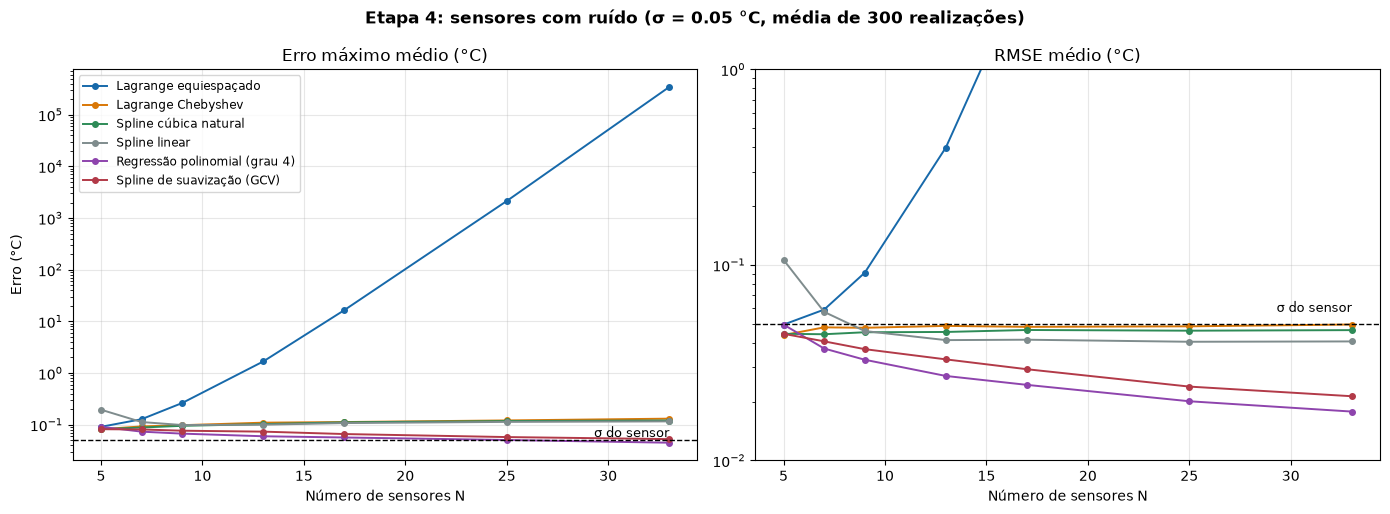

In [15]:
cores_ruido = {"Lagrange equiespaçado": "#1769aa", "Lagrange Chebyshev": "#d97706",
               "Spline cúbica natural": "#2e8b57", "Spline linear": "#7f8c8d",
               "Regressão polinomial (grau 4)": "#8e44ad", "Spline de suavização (GCV)": "#b23a48"}
fig, eixos = plt.subplots(1, 2, figsize=(14, 5.2))
for ax, coluna in zip(eixos, ["Erro máximo médio (°C)", "RMSE médio (°C)"]):
    for nome in ordem_ruido:
        dados = ruido[ruido["Método"] == nome]
        ax.semilogy(dados["N"], dados[coluna], "o-", ms=4, lw=1.4, color=cores_ruido[nome], label=nome)
    ax.axhline(sigma, color="black", ls="--", lw=1)
    ax.text(33, sigma*1.15, "σ do sensor", ha="right", fontsize=9)
    ax.set_xlabel("Número de sensores N"); ax.set_title(coluna)
    ax.grid(True, which="major", alpha=0.3)
eixos[0].set_ylabel("Erro (°C)"); eixos[1].set_ylim(0.01, 1)
eixos[0].legend(fontsize=8.5, loc="upper left")
fig.suptitle(f"Etapa 4: sensores com ruído (σ = {sigma} °C, média de {R} realizações)", weight="bold")
plt.tight_layout(); plt.show()

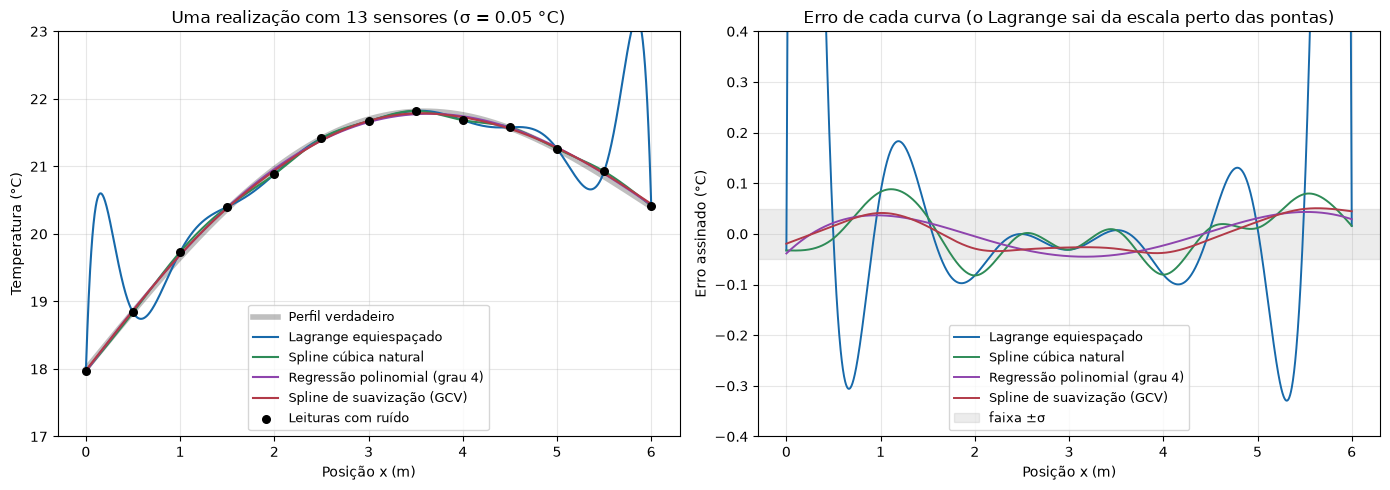

Lagrange equiespaçado        | Emax = 2.665 °C | RMSE = 0.685 °C
Spline cúbica natural        | Emax = 0.088 °C | RMSE = 0.047 °C
Regressão polinomial (grau 4) | Emax = 0.045 °C | RMSE = 0.030 °C
Spline de suavização (GCV)   | Emax = 0.051 °C | RMSE = 0.031 °C


In [16]:
# Uma realização com 13 sensores equiespaçados, para ver o que as médias significam
rng_ex = np.random.default_rng(4)
N_ex = 13
x_ex = np.linspace(x_min, x_max, N_ex)
y_ex = temperatura_real(x_ex) + rng_ex.normal(0, sigma, N_ex)
curvas = {"Lagrange equiespaçado": BarycentricInterpolator(x_ex, y_ex),
          "Spline cúbica natural": CubicSpline(x_ex, y_ex, bc_type="natural"),
          "Regressão polinomial (grau 4)": np.polynomial.Polynomial.fit(x_ex, y_ex, deg=4),
          "Spline de suavização (GCV)": make_smoothing_spline(x_ex, y_ex)}

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5))
ax1.plot(x_fino, T_fino, color="black", lw=4, alpha=0.25, label="Perfil verdadeiro")
for nome, curva in curvas.items():
    ax1.plot(x_fino, curva(x_fino), color=cores_ruido[nome], lw=1.5, label=nome)
ax1.scatter(x_ex, y_ex, color="black", s=30, zorder=5, label="Leituras com ruído")
ax1.set_ylim(17.0, 23.0); ax1.set_xlabel("Posição x (m)"); ax1.set_ylabel("Temperatura (°C)")
ax1.set_title(f"Uma realização com {N_ex} sensores (σ = {sigma} °C)"); ax1.legend(fontsize=9, loc="lower center")
ax1.grid(True, alpha=0.3)
for nome, curva in curvas.items():
    ax2.plot(x_fino, curva(x_fino) - T_fino, color=cores_ruido[nome], lw=1.4, label=nome)
ax2.axhspan(-sigma, sigma, color="gray", alpha=0.15, label="faixa ±σ")
ax2.set_ylim(-0.4, 0.4); ax2.set_xlabel("Posição x (m)"); ax2.set_ylabel("Erro assinado (°C)")
ax2.set_title("Erro de cada curva (o Lagrange sai da escala perto das pontas)"); ax2.grid(True, alpha=0.3)
ax2.legend(fontsize=9, loc="lower center")
plt.tight_layout(); plt.show()

for nome, curva in curvas.items():
    emax, rmse = metricas_erro(curva)
    print(f"{nome:28s} | Emax = {emax:.3f} °C | RMSE = {rmse:.3f} °C")

**O que o experimento mostra** (médias de 300 realizações, $\sigma=0{,}05$ °C):

- **Interpoladores copiam o ruído.** Spline cúbica e Lagrange-Chebyshev ficam com RMSE $\approx0{,}04$ a $0{,}05$ °C (cerca de $\sigma$) e $E_{max}\approx0{,}08$ a $0{,}13$ °C (cerca de $2\sigma$) **com qualquer número de sensores**; a spline linear chega ao mesmo patamar a partir de 9 sensores (com menos, o truncamento dela ainda pesa). Com 33 sensores o RMSE é o mesmo que com 7, e o erro máximo até cresce um pouco, porque há mais pontos onde o ruído pode cair do lado ruim. Cada estimativa entre dois sensores herda o erro deles; mais sensores só trazem mais ruído para copiar.
- **O Lagrange equiespaçado amplifica o ruído** pela constante de Lebesgue: $E_{max}\approx1{,}7$ °C com 13 sensores, $\approx17$ °C com 17 e milhares de graus com 25. Com 9 sensores ele já erra o dobro da spline no RMSE e quase o triplo no $E_{max}$. O erro nasce nas pontas, como se vê na realização acima.
- **Ajustar em vez de interpolar resolve.** A regressão de grau 4 e a spline de suavização ficam **abaixo** de $\sigma$ e melhoram com $N$: o RMSE cai de $\approx0{,}04$ °C com 7 sensores para $\approx0{,}02$ °C com 33. Elas aproveitam a redundância: vários sensores medem a mesma tendência, e os erros independentes se cancelam em parte.
- A regressão de grau 4 ficou um pouco à frente porque **sabemos** que o perfil tem uma só "barriga" e um polinômio de grau 4 o descreve bem. Em campo esse grau teria de ser escolhido e validado; a spline de suavização escolhe o próprio $\lambda$ a partir dos dados, por isso é a opção mais segura quando $T$ é desconhecida. A escolha automática também sofre com o ruído: em alguns sorteios o GCV quase não suaviza e a curva coincide com a spline interpoladora. Na média, porém, ela fica abaixo de $\sigma$.

### Complemento do grupo: interpolação × extrapolação perto das pontas

Se os sensores não cobrem a barra toda, estimar a temperatura entre o último sensor e a extremidade é **extrapolação**. Testamos 5 sensores só no interior ($x=1,2,3,4,5$ m) e comparamos o erro dentro de $[1,5]$ m (interpolação) e nas pontas $[0,1)$ e $(5,6]$ m (extrapolação). Depois repetimos acrescentando as **temperaturas prescritas** $T(0)=18{,}0$ °C e $T(L)=20{,}4$ °C como nós: são condições de contorno conhecidas, não precisam de sensor (no caso com ruído, só os 5 sensores têm ruído).

Caso,Método,"Emax em [1,5] m, exato","Emax nas pontas, exato","Emax em [1,5] m, ruído","Emax nas pontas, ruído"
Só sensores de 1 a 5 m,Lagrange global,4.17e-04,2.40e-02,0.084,0.725
Só sensores de 1 a 5 m,Spline cúbica natural,1.72e-02,3.35e-01,0.083,0.395
Sensores + T(0) e T(L),Lagrange global,1.25e-05,8.47e-05,0.086,0.118
Sensores + T(0) e T(L),Spline cúbica natural,5.06e-04,1.46e-04,0.085,0.061


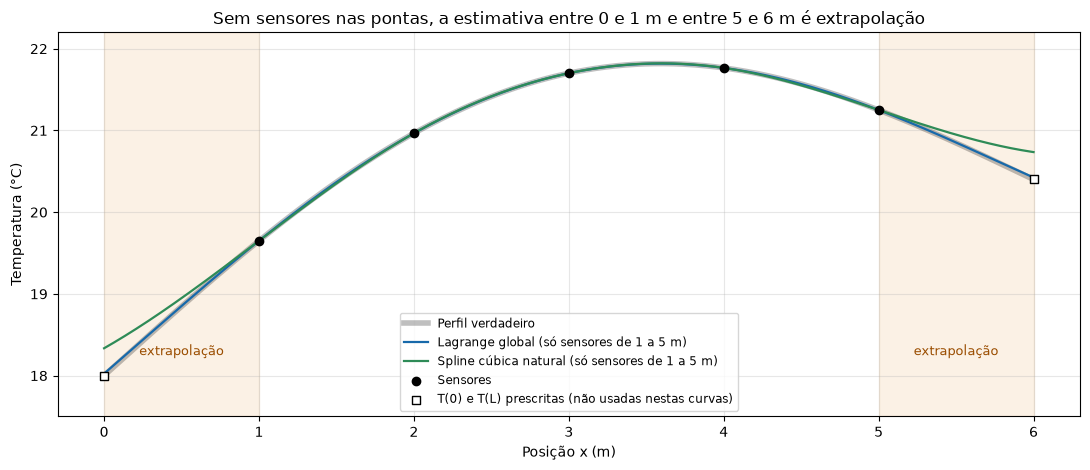

In [17]:
x_int = np.array([1.0, 2.0, 3.0, 4.0, 5.0])     # sensores só no interior da barra
x_com_bordas = np.r_[x_min, x_int, x_max]       # + temperaturas prescritas nas pontas
dentro = (x_fino >= x_int[0]) & (x_fino <= x_int[-1])

def erros_regioes(curva):
    erro = np.abs(curva(x_fino) - T_fino)
    return erro[dentro].max(), erro[~dentro].max()

def leituras(nos, ruidoso):
    y = temperatura_real(nos)
    if ruidoso:
        interior = (nos > x_min) & (nos < x_max)   # as pontas prescritas não têm ruído
        y[interior] += rng.normal(0, sigma, interior.sum())
    return y

metodos_extrap = {"Lagrange global": BarycentricInterpolator,
                  "Spline cúbica natural": lambda x, y: CubicSpline(x, y, bc_type="natural")}
linhas = []
for caso, nos in [("Só sensores de 1 a 5 m", x_int), ("Sensores + T(0) e T(L)", x_com_bordas)]:
    for nome, constroi in metodos_extrap.items():
        exato = erros_regioes(constroi(nos, leituras(nos, False)))
        com_ruido = np.mean([erros_regioes(constroi(nos, leituras(nos, True))) for _ in range(R)], axis=0)
        linhas.append({"Caso": caso, "Método": nome,
                       "Emax em [1,5] m, exato": exato[0], "Emax nas pontas, exato": exato[1],
                       "Emax em [1,5] m, ruído": com_ruido[0], "Emax nas pontas, ruído": com_ruido[1]})
display(pd.DataFrame(linhas).style.format("{:.2e}", subset=pd.IndexSlice[:, ["Emax em [1,5] m, exato", "Emax nas pontas, exato"]])
        .format("{:.3f}", subset=pd.IndexSlice[:, ["Emax em [1,5] m, ruído", "Emax nas pontas, ruído"]]).hide(axis="index"))

fig, ax = plt.subplots(figsize=(11, 4.8))
ax.plot(x_fino, T_fino, color="black", lw=4, alpha=0.25, label="Perfil verdadeiro")
for nome, constroi in metodos_extrap.items():
    ax.plot(x_fino, constroi(x_int, temperatura_real(x_int))(x_fino), color=cores[nome], lw=1.6,
            label=f"{nome} (só sensores de 1 a 5 m)")
ax.scatter(x_int, temperatura_real(x_int), color="black", zorder=5, label="Sensores")
ax.scatter([x_min, x_max], temperatura_real([x_min, x_max]), marker="s", facecolor="white",
           edgecolor="black", zorder=5, label="T(0) e T(L) prescritas (não usadas nestas curvas)")
for a, b in [(x_min, 1.0), (5.0, x_max)]:
    ax.axvspan(a, b, color="#d97706", alpha=0.1)
ax.text(0.5, 18.25, "extrapolação", ha="center", fontsize=9, color="#9a4d00")
ax.text(5.5, 18.25, "extrapolação", ha="center", fontsize=9, color="#9a4d00")
ax.set_ylim(17.5, 22.2); ax.set_xlabel("Posição x (m)"); ax.set_ylabel("Temperatura (°C)")
ax.set_title("Sem sensores nas pontas, a estimativa entre 0 e 1 m e entre 5 e 6 m é extrapolação")
ax.legend(fontsize=8.5, loc="lower center"); ax.grid(True, alpha=0.3); plt.tight_layout(); plt.show()

**Leitura:** com dados exatos, o erro do Lagrange nas pontas é quase 60 vezes o de dentro ($2{,}4\times10^{-2}$ contra $4{,}2\times10^{-4}$ °C); com ruído, cerca de 9 vezes. A spline extrapola ainda pior ($0{,}34$ °C nas pontas, mesmo com dados exatos) e piora também **dentro** do intervalo: ela impõe $S''=0$ em $x=1$ e $x=5$ m, mas ali $T''\neq0$. A condição natural só é correta nas pontas **físicas** da barra.

Acrescentar $T(0)$ e $T(L)$ transforma a extrapolação em interpolação. Com os 7 nós resultantes (0 a 6 m), as curvas são exatamente as da Etapa 1, e o erro nas pontas cai para $8{,}5\times10^{-5}$ °C (Lagrange) e $1{,}5\times10^{-4}$ °C (spline). Com ruído, cai de $0{,}73$ para $0{,}12$ °C (Lagrange) e de $0{,}40$ para $0{,}06$ °C (spline).

## Recomendação técnica do grupo

**Contexto.** Barra de 6 m com as pontas a $18{,}0$ e $20{,}4$ °C, sensores com ruído e perfil verdadeiro desconhecido em campo. As recomendações se apoiam no erro máximo ($E_{max}$) e no RMSE medidos nas Etapas 1 a 4 e nos complementos.

**1. Poucos sensores exatos.** Usaríamos a **spline cúbica natural**, com as temperaturas prescritas das pontas como primeiro e último nó. Com 4 sensores ela tem $E_{max}=1{,}0\times10^{-2}$ °C e RMSE $=4{,}8\times10^{-3}$ °C, enquanto o polinômio global (grau 3) tem $1{,}1\times10^{-1}$ e $6{,}8\times10^{-2}$ °C: dez vezes mais. Até 6 sensores a spline continua na frente ou empata, conforme a métrica. Há dois motivos: um polinômio de grau baixo não acompanha a forma senoidal, e a condição natural $S''=0$ coincide com a física desta barra ($kT''=-\dot q'''=0$ nas pontas). Se a fonte não fosse nula nas pontas, trocaríamos a condição natural pela *not-a-knot* (padrão do `CubicSpline`) ou pela derivada conhecida.

**2. Mais sensores.** Com dados exatos, todos os erros caem, mas de jeitos diferentes. A partir de 7 sensores, o polinômio global passa à frente da spline ($E_{max}$ de $8{,}5\times10^{-5}$ contra $5{,}1\times10^{-4}$ °C). Se pudéssemos escolher as posições, os nós de Chebyshev chegariam ao limite do arredondamento ($\sim10^{-14}$ °C) com 15 sensores. Com sensores igualmente espaçados, porém, o polinômio global piora depois de $N\approx15$ e volta a perder para a spline por volta de $N=36$ ($E_{max}$) ou $N=39$ (RMSE). Aumentar os sensores, portanto, favorece métodos por partes; não usaríamos um polinômio único com dezenas de sensores equiespaçados. E convém lembrar a escala: com 7 sensores exatos, todos os erros já estão abaixo de $10^{-3}$ °C, muito menos que a precisão de um sensor real. Mais sensores servem para enfrentar o ruído, não o truncamento.

**3. Sensores com ruído.** Aqui a recomendação muda de natureza: deixaríamos de **interpolar** e passaríamos a **ajustar**. Com $\sigma=0{,}05$ °C:
- qualquer interpolador copia o ruído: spline cúbica, spline linear e Lagrange-Chebyshev ficam com RMSE $\approx\sigma$ e $E_{max}\approx2\sigma$, **com 7 ou com 33 sensores**;
- o polinômio global equiespaçado amplifica o ruído: $E_{max}\approx1{,}7$ °C com 13 sensores e $\approx17$ °C com 17. É inutilizável;
- a spline de suavização e a regressão de grau 4 ficam **abaixo** do ruído e melhoram com $N$ (RMSE de $\approx0{,}04$ °C com 7 sensores para $\approx0{,}02$ °C com 33).

Escolheríamos a **spline de suavização**, que não exige adivinhar o grau do modelo. Além disso, estimaríamos $\sigma$ com leituras repetidas (a média de $n$ leituras tem desvio $\sigma/\sqrt n$) e calibraríamos os sensores, porque um desvio sistemático (viés) não é removido por nenhum desses métodos.

**4. Cuidados perto das extremidades.**
- Usar as **temperaturas prescritas** $T(0)$ e $T(L)$ como dados. Com sensores só entre 1 e 5 m, incluí-las reduziu o $E_{max}$ nas pontas de $2{,}4\times10^{-2}$ para $8{,}5\times10^{-5}$ °C (Lagrange) e de $0{,}34$ para $1{,}5\times10^{-4}$ °C (spline) com dados exatos, e de $0{,}73$ para $0{,}12$ °C (Lagrange) com ruído, porque a estimativa ali deixa de ser extrapolação.
- Evitar o polinômio global com nós equiespaçados: é nas pontas que ele mais erra com dados exatos (Etapa 1) e é nas pontas que ele amplifica o ruído (Etapa 4).
- Se for possível escolher onde instalar, **concentrar sensores perto das pontas**, que é a ideia dos nós de Chebyshev.
- Não usar a condição natural longe das pontas físicas: com sensores só entre 1 e 5 m, a spline natural impõe $S''=0$ onde $T''\neq0$, e o erro dela subiu até dentro do intervalo medido.

**5. Limitações quando a temperatura verdadeira não é conhecida.**
- Em campo não dá para calcular $E_{max}$ nem RMSE, porque eles exigem $T(x)$. O que se pode fazer é **estimar** o erro: validação cruzada (tirar um sensor, prever o valor dele com os demais e comparar), sensores extras reservados para validação e comparação entre métodos (onde eles discordam, a incerteza é grande).
- As cotas teóricas da Etapa 1 dependem de derivadas de $T$ que não conhecemos.
- Enquanto interpolamos, o erro entre sensores não fica abaixo do ruído; só um modelo (regressão, suavização ou a própria equação do calor) aproveita a redundância das medições.
- O perfil analítico é idealizado. Uma barra real tem perdas por convecção, $k$ que varia com a temperatura, fonte não uniforme e regime transitório. Um aquecimento localizado ou um "bico" no perfil derrubaria o desempenho do polinômio global, como a função de Runge da atividade anterior.

**Interpolação × extrapolação.** Dentro do intervalo coberto pelos sensores, o erro é controlado pelos dados vizinhos; fora dele, nada segura a curva. No nosso teste (sensores entre 1 e 5 m), o $E_{max}$ do Lagrange nas pontas foi quase 60 vezes o de dentro com dados exatos e cerca de 9 vezes com ruído. Na barra, a regra é cobrir as pontas com dados (sensor ou condição de contorno) e não usar a curva além de $0\le x\le L$, onde o modelo físico nem vale.

### Resumo: o Python usado nesta atividade

| Onde | Conceito |
|---|---|
| Complemento da seção 2 | diferença central para conferir uma derivada; erro de arredondamento ao dividir por $h^2$ |
| Etapa 1 | `pd.set_option("display.float_format", ...)` para tabelas em notação científica; `plt.subplots` com zoom; `ticklabel_format` |
| Complemento da Etapa 1 | `np.prod` sobre uma lista de vetores para montar $\omega(x)$; `math.factorial` |
| Etapa 2 | função com argumentos padrão (`metricas_erro`); `DataFrame.style.format`; `semilogy` |
| Etapa 3 | `time.perf_counter` e o menor de várias repetições; dicionário de funções (`construtores`); `pivot` e `idxmin` |
| Complemento da Etapa 3 | constante de Lebesgue: interpolar vetores da base canônica |
| Etapa 4 | `np.random.default_rng(semente)` para ruído reprodutível; Monte Carlo com `R` realizações; `make_smoothing_spline` |